In [1]:
pip install pymysql

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.7/46.7 kB 2.8 MB/s eta 0:00:00


In [2]:
import pymysql
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
connection =  pymysql.connect(
    host="vmlp.pwdlearning.cloud",
    user="student_ds",
    password="@studentDS#2026",
    port=3306,
    cursorclass= pymysql.cursors.DictCursor,
    database="tokopedia"
)

print('connection successful')

connection successful


In [4]:
cursor = connection.cursor()

cursor.execute("SHOW DATABASES")
database = cursor.fetchall()

for db in database:
  print(db)

{'Database': 'alfamart'}
{'Database': 'bluebird'}
{'Database': 'dekoruma'}
{'Database': 'information_schema'}
{'Database': 'performance_schema'}
{'Database': 'sinarmasland'}
{'Database': 'tokopedia'}


In [5]:
database_name = "tokopedia"

# get all tables from tokopedia
cursor.execute(f"SHOW TABLES FROM `{database_name}`")
tables = cursor.fetchall()

for table in tables:
    print(table)

{'Tables_in_tokopedia': 'customer_service_tickets'}
{'Tables_in_tokopedia': 'deliveries'}
{'Tables_in_tokopedia': 'sellers'}
{'Tables_in_tokopedia': 'transactions'}
{'Tables_in_tokopedia': 'users'}


In [6]:
for table in tables:
    table_name = table[f"Tables_in_{database_name}"]
    print(f"\n--- {table_name} ---")

    cursor.execute(f"DESCRIBE `{database_name}`.`{table_name}`")
    columns = cursor.fetchall()

    df_columns = pd.DataFrame(columns)
    display(df_columns)


--- customer_service_tickets ---


,Field,Type,Null,Key,Default,Extra
0,ticket_key,bigint,NO,PRI,None,auto_increment
1,ticket_id,varchar(20),NO,UNI,None,
2,order_id,varchar(25),NO,MUL,None,
3,complaint_category,varchar(20),YES,MUL,None,
4,ticket_date,date,YES,,None,
5,channel,varchar(15),YES,,None,
6,resolution_status,varchar(15),YES,,None,
7,resolution_time_hours,"decimal(6,1)",YES,,None,
8,csat_score,smallint,YES,,None,
9,agent_id,varchar(15),YES,,None,



--- deliveries ---


,Field,Type,Null,Key,Default,Extra
0,delivery_key,bigint,NO,PRI,None,auto_increment
1,order_id,varchar(25),NO,MUL,None,
2,courier_name,varchar(20),YES,MUL,None,
3,dispatch_date,date,YES,,None,
4,delivery_date,date,YES,,None,
5,destination_city,varchar(20),YES,,None,
6,delivery_status,varchar(15),YES,,None,
7,sla_promised_days,smallint,YES,,None,
8,courier_service_type,varchar(15),YES,,None,
9,shipping_zone,varchar(15),YES,MUL,None,



--- sellers ---


,Field,Type,Null,Key,Default,Extra
0,seller_id,varchar(40),NO,PRI,None,
1,seller_name,varchar(50),YES,,None,
2,seller_city,varchar(20),YES,,None,
3,seller_join_date,date,YES,,None,
4,is_official_store,tinyint(1),YES,,None,
5,seller_rating,"decimal(3,2)",YES,,None,
6,category_focus,varchar(20),YES,MUL,None,
7,avg_response_time_hours,"decimal(6,1)",YES,,None,
8,seller_status,varchar(20),YES,,None,



--- transactions ---


,Field,Type,Null,Key,Default,Extra
0,transaction_key,bigint,NO,PRI,None,auto_increment
1,order_id,varchar(25),NO,MUL,None,
2,user_id,varchar(10),YES,MUL,None,
3,order_date,date,YES,MUL,None,
4,payment_method,varchar(20),YES,,None,
5,promo_amount,int,YES,,None,
6,total_amount,bigint,YES,,None,
7,product_category,varchar(20),YES,,None,
8,item_quantity,smallint,YES,,None,
9,seller_id,varchar(40),NO,MUL,None,



--- users ---


,Field,Type,Null,Key,Default,Extra
0,user_id,varchar(10),NO,PRI,None,
1,join_date,date,YES,,None,
2,gender,varchar(10),YES,,None,
3,location,varchar(20),YES,MUL,None,
4,province,varchar(20),YES,,None,
5,age,smallint,YES,,None,
6,device_type,varchar(10),YES,,None,
7,acquisition_channel,varchar(20),YES,MUL,None,
8,phone_verified,tinyint(1),YES,,None,
9,email_verified,tinyint(1),YES,,None,


In [7]:
for table in tables:
  table_name = table[f"Tables_in_{database_name}"]
  print(f"\n--- {table_name} ---")
  cursor.execute(f"""
  select *
  from `{database_name}`.`{table_name}`
  limit 5
  """)

  result = cursor.fetchall()
  df = pd.DataFrame(result)
  display(df)


--- customer_service_tickets ---


,ticket_key,ticket_id,order_id,complaint_category,ticket_date,channel,resolution_status,resolution_time_hours,csat_score,agent_id
0,1,TKT-230118-9023,INV/230110/7638135,refund,2023-01-18,sosmed,resolved,8.3,2.0,AG-MDN-010
1,2,TKT-230112-8941,INV/230105/1066246,produk_rusak,2023-01-12,telepon,resolved,633.6,4.0,AG-SBY-014
2,3,TKT-240814-3460,INV/240804/3988656,lainnya,2024-08-14,telepon,resolved,0.8,NaN,AG-MKS-003
3,4,TKT-230305-3826,INV/230301/2429766,keterlambatan,2023-03-05,email,resolved,31.8,1.0,AG-BDG-002
4,5,TKT-230124-4529,INV/230101/8089124,keterlambatan,2023-01-24,sosmed,resolved,85.1,3.0,AG-SBY-010



--- deliveries ---


,delivery_key,order_id,courier_name,dispatch_date,delivery_date,destination_city,delivery_status,sla_promised_days,courier_service_type,shipping_zone,courier_rating
0,1,INV/230725/5419223,SiCepat,2023-07-25,2023-07-25,Malang,delivered,2,express,dalam_kota,5.0
1,2,INV/230707/2520159,GoTo Logistics,2023-07-08,2023-07-11,Padang,delivered,3,instant,luar_kota,4.7
2,3,INV/230506/9664059,JNE,2023-05-12,2023-05-22,Surabaya,returned,10,reguler,luar_pulau,4.6
3,4,INV/231220/6168058,JNE,2023-12-20,2023-12-24,JAKARTA,in_transit,3,reguler,luar_kota,None
4,5,INV/230212/6496572,GoTo Logistics,2023-02-13,2023-02-20,Surabaya,delivered,7,reguler,luar_pulau,4.7



--- sellers ---


,seller_id,seller_name,seller_city,seller_join_date,is_official_store,seller_rating,category_focus,avg_response_time_hours,seller_status
0,adhiarja-store-6855,Adhiarja Store,Medan,2019-10-06,0,4.10,grocery,15.3,active
1,adika-8914,Adika,Tangerang,2023-02-16,1,4.17,grocery,8.2,active
2,adinata-3700,Adinata,Yogyakarta,2019-01-04,0,5.00,elektronik,1.6,active
3,adinata-7206,Adinata,Medan,2020-02-03,0,4.76,grocery,1.1,active
4,adinata-official-5770,Adinata Official,Yogyakarta,2023-04-08,0,4.25,lainnya,8.7,active



--- transactions ---


,transaction_key,order_id,user_id,order_date,payment_method,promo_amount,total_amount,product_category,item_quantity,seller_id,shipping_cost_charged_to_user,shipping_subsidy_platform,voucher_type,payment_channel_provider,order_status,is_campaign_period,device_used
0,1,INV/240811/8962287,LFXY4QKTAM,2024-08-11,Bank Transfer,14804,920008,lainnya,2,anggun-store-5040,8387,1581,cashback,Bank Transfer,completed,0,Android
1,2,INV/230311/4418494,TRFUZBU6U8,2023-03-11,cod,5382,366818,grocery,3,jais-mart-5341,9400,2593,cashback,COD,completed,0,Android
2,3,INV/230114/7544472,K22YYHXLTT,2023-01-14,ShopeePay,20450,412180,fashion,1,cinnamon-outfit-shop-4530,8490,2125,cashback,ShopeePay,completed,0,Android
3,4,INV/240207/1913666,TRZQBBETNL,2024-02-07,COD,0,495980,kesehatan,4,wisesa-store-1371,12891,9391,None,COD,returned,0,iOS
4,5,INV/231111/7533488,25HB82C54C,2023-11-11,GoPay,24830,182024,grocery,2,kalyca-mart-boutique-5885,3422,16201,diskon_persen,GoPay,completed,1,Android



--- users ---


,user_id,join_date,gender,location,province,age,device_type,acquisition_channel,phone_verified,email_verified,referral_code_used,account_status,last_active_date
0,222FPT2RQE,2024-12-07,Female,Surabaya,Jawa Timur,35,Android,ads,1,1,None,active,2024-12-09
1,222TKKG47G,2023-11-10,Female,Surabaya,Jawa Timur,46,Android,organic,1,1,None,active,2023-12-02
2,2242MWUZJL,2023-10-14,Female,Manado,Sulawesi Utara,41,Android,affiliate,1,0,None,active,2023-10-27
3,224JW2JMEQ,2024-10-05,Male,Medan,Sumatera Utara,65,Android,referral,1,1,SVHZNJ,active,2024-10-13
4,224RUVDYHV,2020-12-19,Male,DKI Jakarta,DKI Jakarta,51,Android,ads,1,1,None,active,2021-01-15


In [8]:
dataframes = {}

for table in tables:
    table_name = table[f"Tables_in_{database_name}"]

    cursor.execute(f"select * from `{database_name}`.`{table_name}`")
    result = cursor.fetchall()

    df = pd.DataFrame(result)
    dataframes[table_name] = df

    print(f"\n--- {table_name} ---")
    print("Total rows:", len(df))
    print("Total columns:", len(df.columns))
    print("Total NULL values:", df.isnull().sum().sum())
    print("Total duplicate rows:", df.duplicated().sum())

    print("\nNULL values per column:")
    print(df.isnull().sum().to_frame(name="null_count"))

    print("\nDuplicate rows:")
    print(df[df.duplicated()])


--- customer_service_tickets ---
Total rows: 31553
Total columns: 10
Total NULL values: 9969
Total duplicate rows: 0

NULL values per column:
                       null_count
ticket_key                      0
ticket_id                       0
order_id                        0
complaint_category              0
ticket_date                     0
channel                         0
resolution_status               0
resolution_time_hours           0
csat_score                   9969
agent_id                        0

Duplicate rows:
Empty DataFrame
Columns: [ticket_key, ticket_id, order_id, complaint_category, ticket_date, channel, resolution_status, resolution_time_hours, csat_score, agent_id]
Index: []

--- deliveries ---
Total rows: 261525
Total columns: 11
Total NULL values: 87821
Total duplicate rows: 0

NULL values per column:
                      null_count
delivery_key                   0
order_id                       0
courier_name                9977
dispatch_date               

In [9]:
def load_table(table_name):
    cursor.execute(f"select * from `{table_name}`")
    data = cursor.fetchall()
    return pd.DataFrame(data)

users = load_table("users")
transactions = load_table("transactions")
deliveries = load_table("deliveries")
sellers = load_table("sellers")
tickets = load_table("customer_service_tickets")

In [10]:
users.head()

,user_id,join_date,gender,location,province,age,device_type,acquisition_channel,phone_verified,email_verified,referral_code_used,account_status,last_active_date
0,222FPT2RQE,2024-12-07,Female,Surabaya,Jawa Timur,35,Android,ads,1,1,None,active,2024-12-09
1,222TKKG47G,2023-11-10,Female,Surabaya,Jawa Timur,46,Android,organic,1,1,None,active,2023-12-02
2,2242MWUZJL,2023-10-14,Female,Manado,Sulawesi Utara,41,Android,affiliate,1,0,None,active,2023-10-27
3,224JW2JMEQ,2024-10-05,Male,Medan,Sumatera Utara,65,Android,referral,1,1,SVHZNJ,active,2024-10-13
4,224RUVDYHV,2020-12-19,Male,DKI Jakarta,DKI Jakarta,51,Android,ads,1,1,None,active,2021-01-15


In [60]:
# 1. Merge the date columns from both tables using order_id
df_dates = pd.merge(
    transactions[['order_id', 'order_date']],
    deliveries[['order_id', 'dispatch_date', 'delivery_date']],
    on='order_id',
    how='inner'
)

# 2. Ensure all columns are datetime objects for accurate comparison
df_dates['order_date'] = pd.to_datetime(df_dates['order_date'])
df_dates['dispatch_date'] = pd.to_datetime(df_dates['dispatch_date'])
df_dates['delivery_date'] = pd.to_datetime(df_dates['delivery_date'])

# 3. Filter for logical anomalies
dispatched_before_ordered = df_dates[df_dates['dispatch_date'] < df_dates['order_date']]
delivered_before_dispatched = df_dates[df_dates['delivery_date'] < df_dates['dispatch_date']]

# 4. Print the anomaly report
print("--- DATE ANOMALY REPORT ---")
print(f"Error Type 1 (Dispatch < Order Date): {len(dispatched_before_ordered)} rows")
print(f"Error Type 2 (Delivery < Dispatch Date): {len(delivered_before_dispatched)} rows")

# Optional: View a sample of the bad data if it exists
if len(dispatched_before_ordered) > 0:
    display(dispatched_before_ordered.head())

--- DATE ANOMALY REPORT ---
Error Type 1 (Dispatch < Order Date): 908 rows
Error Type 2 (Delivery < Dispatch Date): 0 rows


,order_id,order_date,dispatch_date,delivery_date
65,INV/240225/5646211,2024-02-25,2024-02-22,2024-02-24
335,INV/240929/8132496,2024-09-29,2024-09-25,2024-09-27
572,INV/230202/4201986,2030-04-13,2023-02-03,2023-02-04
577,INV/240413/7589062,2024-04-13,2024-04-12,2024-04-13
638,INV/230225/9637161,2030-09-12,2023-02-25,2023-02-28


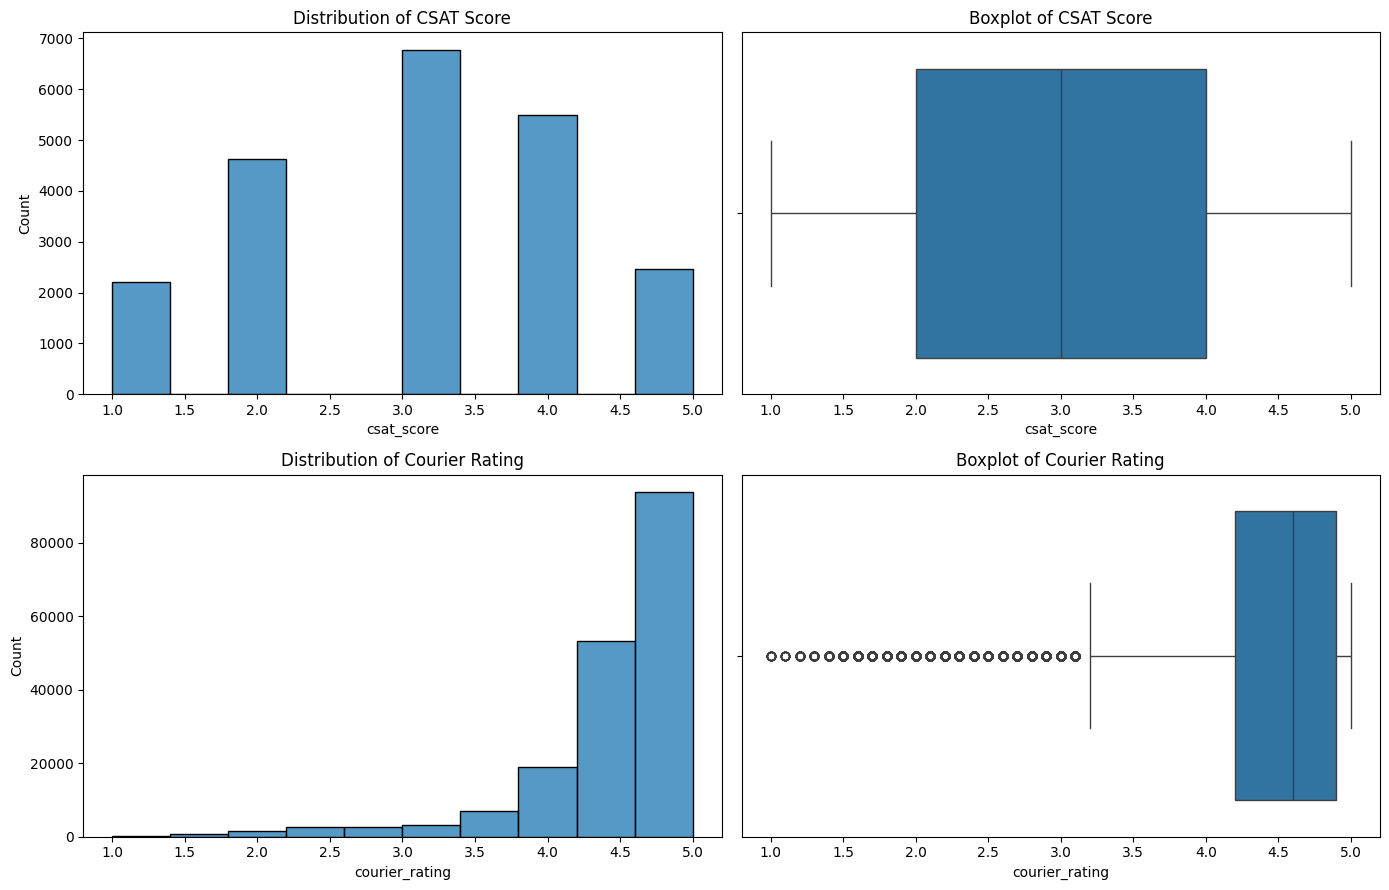

In [11]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(2, 2, figsize=(14, 9))

# CSAT score distribution
sns.histplot(data=tickets, x="csat_score", bins=10, ax=axes[0, 0])
axes[0, 0].set_title("Distribution of CSAT Score")

sns.boxplot(data=tickets, x="csat_score", ax=axes[0, 1])
axes[0, 1].set_title("Boxplot of CSAT Score")

# Courier rating distribution
sns.histplot(data=deliveries, x="courier_rating", bins=10, ax=axes[1, 0])
axes[1, 0].set_title("Distribution of Courier Rating")

sns.boxplot(data=deliveries, x="courier_rating", ax=axes[1, 1])
axes[1, 1].set_title("Boxplot of Courier Rating")

plt.tight_layout()
plt.show()

In [50]:
def check_outliers_iqr(df, column):
    # Calculate Q1, Q3, and IQR
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)
    IQR = Q3 - Q1

    # Define upper and lower bounds
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    # Count outliers
    outliers = df[(df[column] < lower_bound) | (df[column] > upper_bound)]
    outlier_percentage = (len(outliers) / len(df)) * 100

    print(f"--- {column.upper()} ---")
    print(f"IQR Range: {lower_bound:.2f} to {upper_bound:.2f}")
    print(f"Total Outliers: {len(outliers)} rows ({outlier_percentage:.2f}% of data)\n")

    return lower_bound, upper_bound

# Key financial and quantity columns to check
numeric_cols = [
    "promo_amount",
    "total_amount",
    "item_quantity",
    "shipping_cost_charged_to_user",
    "shipping_subsidy_platform"
]

print("OUTLIER DETECTION REPORT\\n")
for col in numeric_cols:
    check_outliers_iqr(transactions, col)

OUTLIER DETECTION REPORT\n
--- PROMO_AMOUNT ---
IQR Range: -32640.00 to 54400.00
Total Outliers: 20778 rows (7.70% of data)

--- TOTAL_AMOUNT ---
IQR Range: -857299.00 to 1911173.00
Total Outliers: 37118 rows (13.75% of data)

--- ITEM_QUANTITY ---
IQR Range: -2.00 to 6.00
Total Outliers: 591 rows (0.22% of data)

--- SHIPPING_COST_CHARGED_TO_USER ---
IQR Range: -6978.50 to 25865.50
Total Outliers: 0 rows (0.00% of data)

--- SHIPPING_SUBSIDY_PLATFORM ---
IQR Range: -8119.50 to 21716.50
Total Outliers: 2761 rows (1.02% of data)



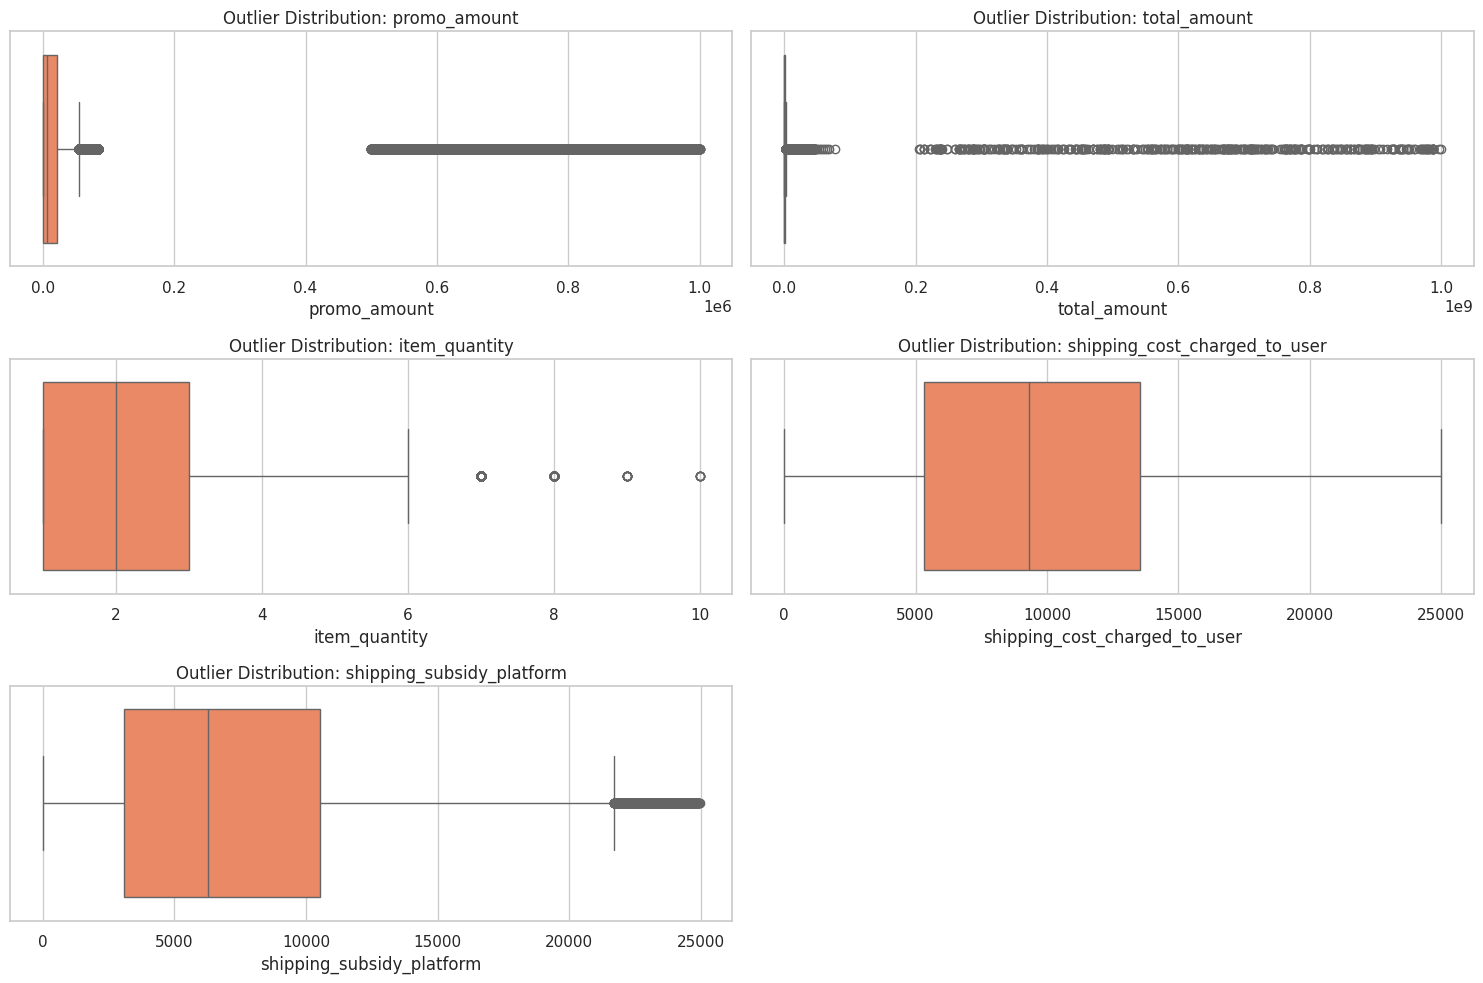

In [48]:
plt.figure(figsize=(15, 10))

for i, col in enumerate(numeric_cols, 1):
    plt.subplot(3, 2, i)
    sns.boxplot(x=transactions[col], color='coral')
    plt.title(f'Outlier Distribution: {col}')

plt.tight_layout()
plt.show()

In [12]:
print(tickets["csat_score"].dtype)
print(tickets["csat_score"].value_counts(dropna=False).head(10))

print(deliveries["courier_rating"].dtype)
print(deliveries["courier_rating"].value_counts(dropna=False).head(10))

float64
csat_score
NaN    9969
3.0    6782
4.0    5498
2.0    4628
5.0    2471
1.0    2205
Name: count, dtype: int64
object
courier_rating
None    77844
5.0     34562
4.6     16307
4.7     15947
4.5     15722
4.4     14435
4.8     14366
4.3     12787
4.9     12652
4.2     10383
Name: count, dtype: int64


In [13]:
for name, series in {
    "CSAT Score": tickets["csat_score"],
    "Courier Rating": deliveries["courier_rating"]
}.items():
    print(f"\n{name}")
    print("Mean:", series.mean())
    print("Median:", series.median())
    print("Skewness:", series.skew())
    print("Missing:", series.isna().sum())


CSAT Score
Mean: 3.06495552260934
Median: 3.0
Skewness: -0.07865503138379576
Missing: 9969

Courier Rating
Mean: 4.44281771114051
Median: 4.6
Skewness: -2.1277919974380053
Missing: 77844


In [14]:
# users
users["gender"] = users["gender"].fillna("unknown")
users["referral_code_used"] = users["referral_code_used"].fillna("no referral")

# transactions
transactions["voucher_type"] = np.where(
    transactions["voucher_type"].isna() & (transactions["promo_amount"] == 0),
    "no voucher", transactions["voucher_type"])
transactions["voucher_type"] = transactions["voucher_type"].fillna("unknown")

# deliveries
deliveries["courier_name"] = deliveries["courier_name"].fillna("unknown")
deliveries["courier_rating"] = deliveries["courier_rating"].fillna(deliveries["courier_rating"].median())

# customer service tickets
tickets["csat_score"] = tickets["csat_score"].fillna(tickets["csat_score"].median())



,Order Status,Count
0,completed,237039
1,refund,15227
2,returned,10310
3,cancelled,7377


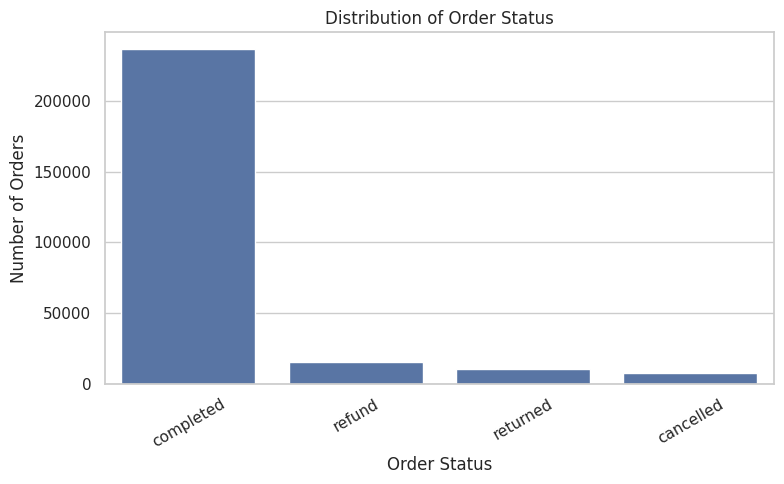

In [24]:
status_count = (
    transactions["order_status"]
    .value_counts()
    .reset_index()
)

status_count.columns = ["Order Status", "Count"]

display(status_count)

plt.figure(figsize=(8, 5))

sns.barplot(
    data=status_count,
    x="Order Status",
    y="Count"
)

plt.title("Distribution of Order Status")
plt.xlabel("Order Status")
plt.ylabel("Number of Orders")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

In [26]:
numerical_cols = [
    "promo_amount",
    "total_amount",
    "item_quantity",
    "shipping_cost_charged_to_user",
    "shipping_subsidy_platform"
]

display(
    transactions[numerical_cols].describe().T
)

,count,mean,std,min,25%,50%,75%,max
promo_amount,269953.0,5.423251e+04,1.766650e+05,0.0,0.0,6885.0,21760.0,999993.0
total_amount,269953.0,2.190434e+06,2.596290e+07,-199974.0,180878.0,356533.0,872996.0,999793731.0
item_quantity,269953.0,2.297359e+00,1.139983e+00,1.0,1.0,2.0,3.0,10.0
shipping_cost_charged_to_user,269953.0,9.658226e+03,5.592767e+03,1.0,5338.0,9327.0,13549.0,24984.0
shipping_subsidy_platform,269953.0,7.339796e+03,5.331626e+03,0.0,3069.0,6286.0,10528.0,24955.0


In [28]:
categorical_cols = [
    "payment_method",
    "payment_channel_provider",
    "voucher_type",
    "product_category",
    "order_status",
    "device_used",
    "is_campaign_period"
]

for col in categorical_cols:
    print(f"\n{col}")
    display(
        transactions[col]
        .value_counts(dropna=False)
        .to_frame("Count")
    )


payment_method


,Count
payment_method,
Bank Transfer,48232
COD,45753
GoPay,39123
QRIS,35325
OVO,24753
ShopeePay,22307
DANA,19868
Credit Card,12360
qris,2209



payment_channel_provider


,Count
payment_channel_provider,
Bank Transfer,53618
COD,49664
GoPay,43000
QRIS,37534
OVO,26931
ShopeePay,24252
DANA,21553
Credit Card,13401



voucher_type


...

,Count
order_status,
completed,237039
refund,15227
returned,10310
cancelled,7377



device_used


,Count
device_used,
Android,183552
iOS,61774
Web,24627



is_campaign_period


,Count
is_campaign_period,
0,171644
1,98309


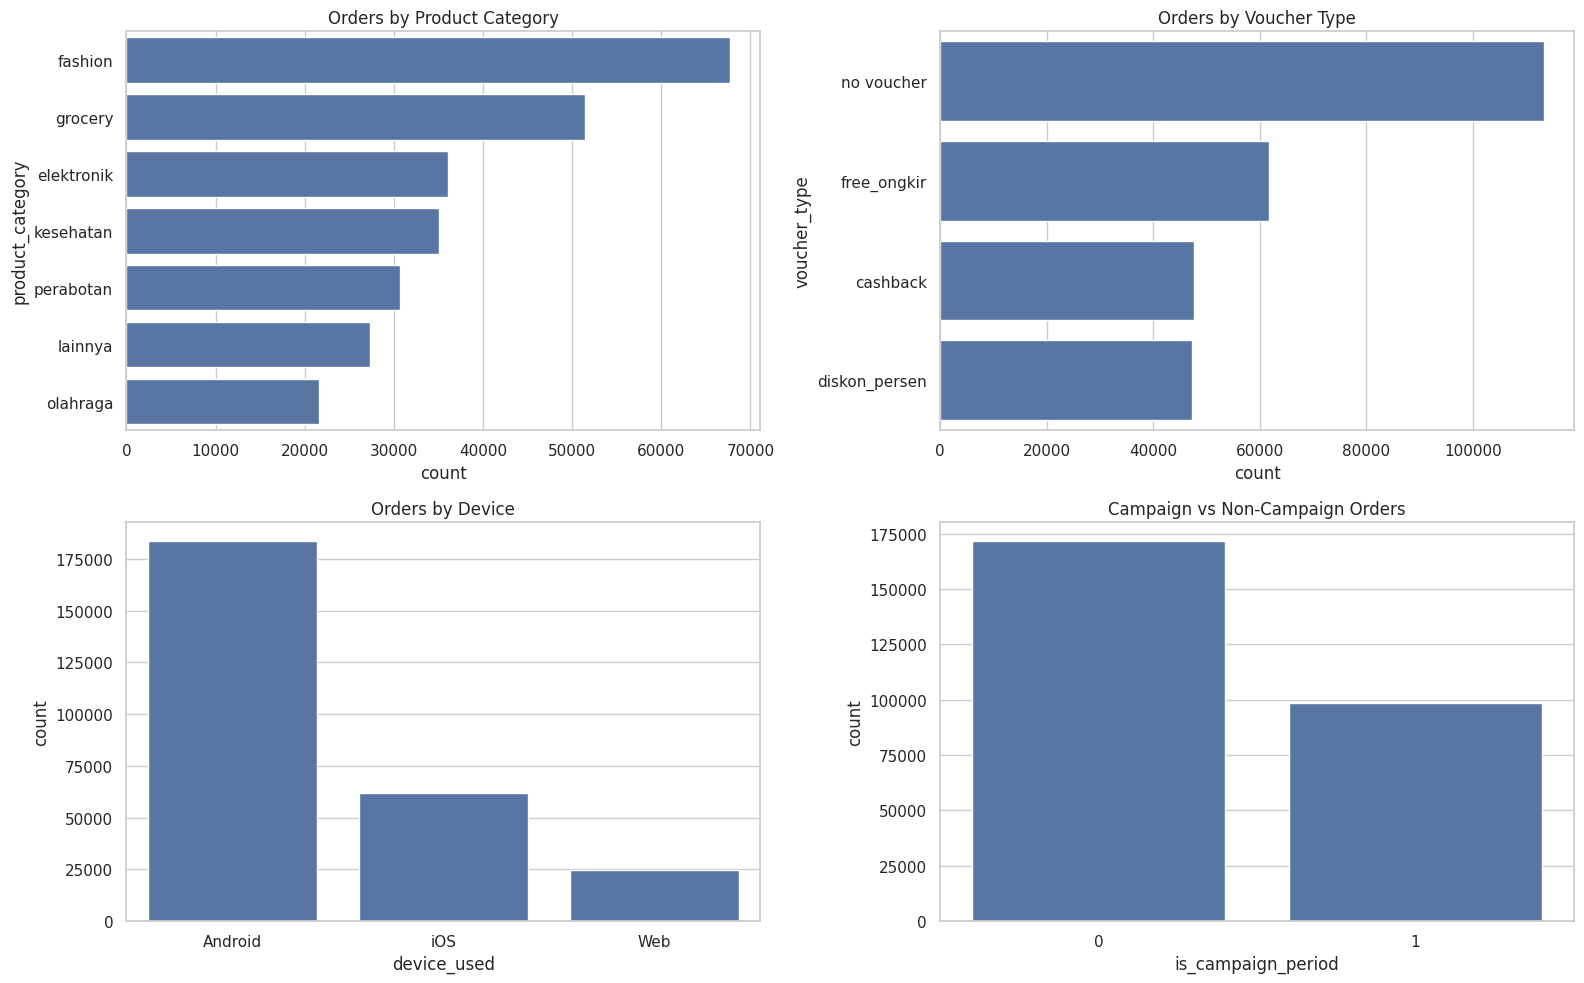

In [29]:
fig, axes = plt.subplots(2, 2, figsize=(16, 10))

sns.countplot(
    data=transactions,
    y="product_category",
    order=transactions["product_category"]
        .value_counts().index,
    ax=axes[0, 0]
)
axes[0, 0].set_title("Orders by Product Category")

sns.countplot(
    data=transactions,
    y="voucher_type",
    order=transactions["voucher_type"]
        .value_counts().index,
    ax=axes[0, 1]
)
axes[0, 1].set_title("Orders by Voucher Type")

sns.countplot(
    data=transactions,
    x="device_used",
    ax=axes[1, 0]
)
axes[1, 0].set_title("Orders by Device")

sns.countplot(
    data=transactions,
    x="is_campaign_period",
    ax=axes[1, 1]
)
axes[1, 1].set_title("Campaign vs Non-Campaign Orders")

plt.tight_layout()
plt.show()

/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


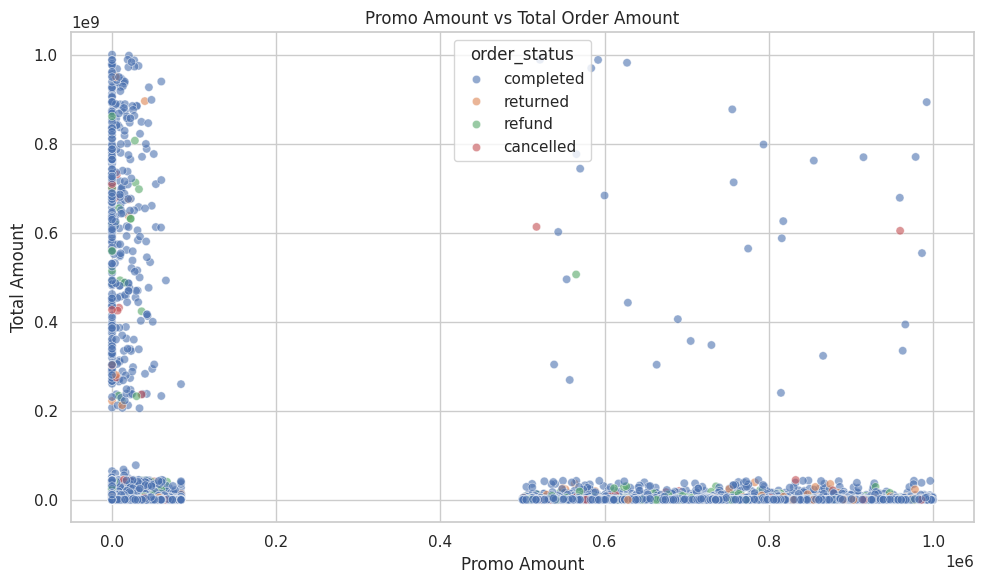

In [30]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=transactions,
    x="promo_amount",
    y="total_amount",
    hue="order_status",
    alpha=0.6
)

plt.title("Promo Amount vs Total Order Amount")
plt.xlabel("Promo Amount")
plt.ylabel("Total Amount")
plt.tight_layout()
plt.show()

In [31]:
completed = transactions[
    transactions["order_status"].eq("completed")
].copy()

campaign_analysis = (
    completed.groupby("is_campaign_period")
    .agg(
        completed_orders=("order_id", "nunique"),
        unique_users=("user_id", "nunique"),
        total_gmv=("total_amount", "sum"),
        avg_order_value=("total_amount", "mean"),
        total_promo=("promo_amount", "sum"),
        total_shipping_subsidy=(
            "shipping_subsidy_platform", "sum"
        )
    )
    .reset_index()
)

campaign_analysis["promo_per_order"] = (
    campaign_analysis["total_promo"]
    / campaign_analysis["completed_orders"]
)

campaign_analysis["subsidy_per_order"] = (
    campaign_analysis["total_shipping_subsidy"]
    / campaign_analysis["completed_orders"]
)

display(campaign_analysis)

,is_campaign_period,completed_orders,unique_users,total_gmv,avg_order_value,total_promo,total_shipping_subsidy,promo_per_order,subsidy_per_order
0,0,150724,46324,336804614900,2.234504e+06,7939902648,639202200,52678.423131,4240.878692
1,1,85356,36420,190092054048,2.202434e+06,4946051740,1100341162,57946.151882,12891.198768


In [32]:
completed_users = completed.merge(
    users[["user_id", "acquisition_channel"]],
    on="user_id",
    how="left",
    validate="many_to_one"
)

channel_analysis = (
    completed_users.groupby("acquisition_channel")
    .agg(
        users=("user_id", "nunique"),
        orders=("order_id", "nunique"),
        gmv=("total_amount", "sum"),
        promo_spend=("promo_amount", "sum"),
        shipping_subsidy=(
            "shipping_subsidy_platform", "sum"
        )
    )
    .reset_index()
)

channel_analysis["promo_per_order"] = (
    channel_analysis["promo_spend"]
    / channel_analysis["orders"]
)

channel_analysis["promo_per_user"] = (
    channel_analysis["promo_spend"]
    / channel_analysis["users"]
)

channel_analysis["gmv_per_user"] = (
    channel_analysis["gmv"]
    / channel_analysis["users"]
)

display(
    channel_analysis.sort_values(
        "promo_spend", ascending=False
    )
)

,acquisition_channel,users,orders,gmv,promo_spend,shipping_subsidy,promo_per_order,promo_per_user,gmv_per_user
2,organic,22864,99267,221283885592,5392489085,727974455,54323.079019,235850.642276,9.678267e+06
0,ads,15539,77693,170324210863,4302851925,574303358,55382.749089,276906.617221,1.096108e+07
3,referral,7710,34842,81809775288,1921561436,258369181,55150.721428,249229.758236,1.061087e+07
1,affiliate,5103,23938,52335484878,1253243742,176429966,52353.736402,245589.602587,1.025583e+07


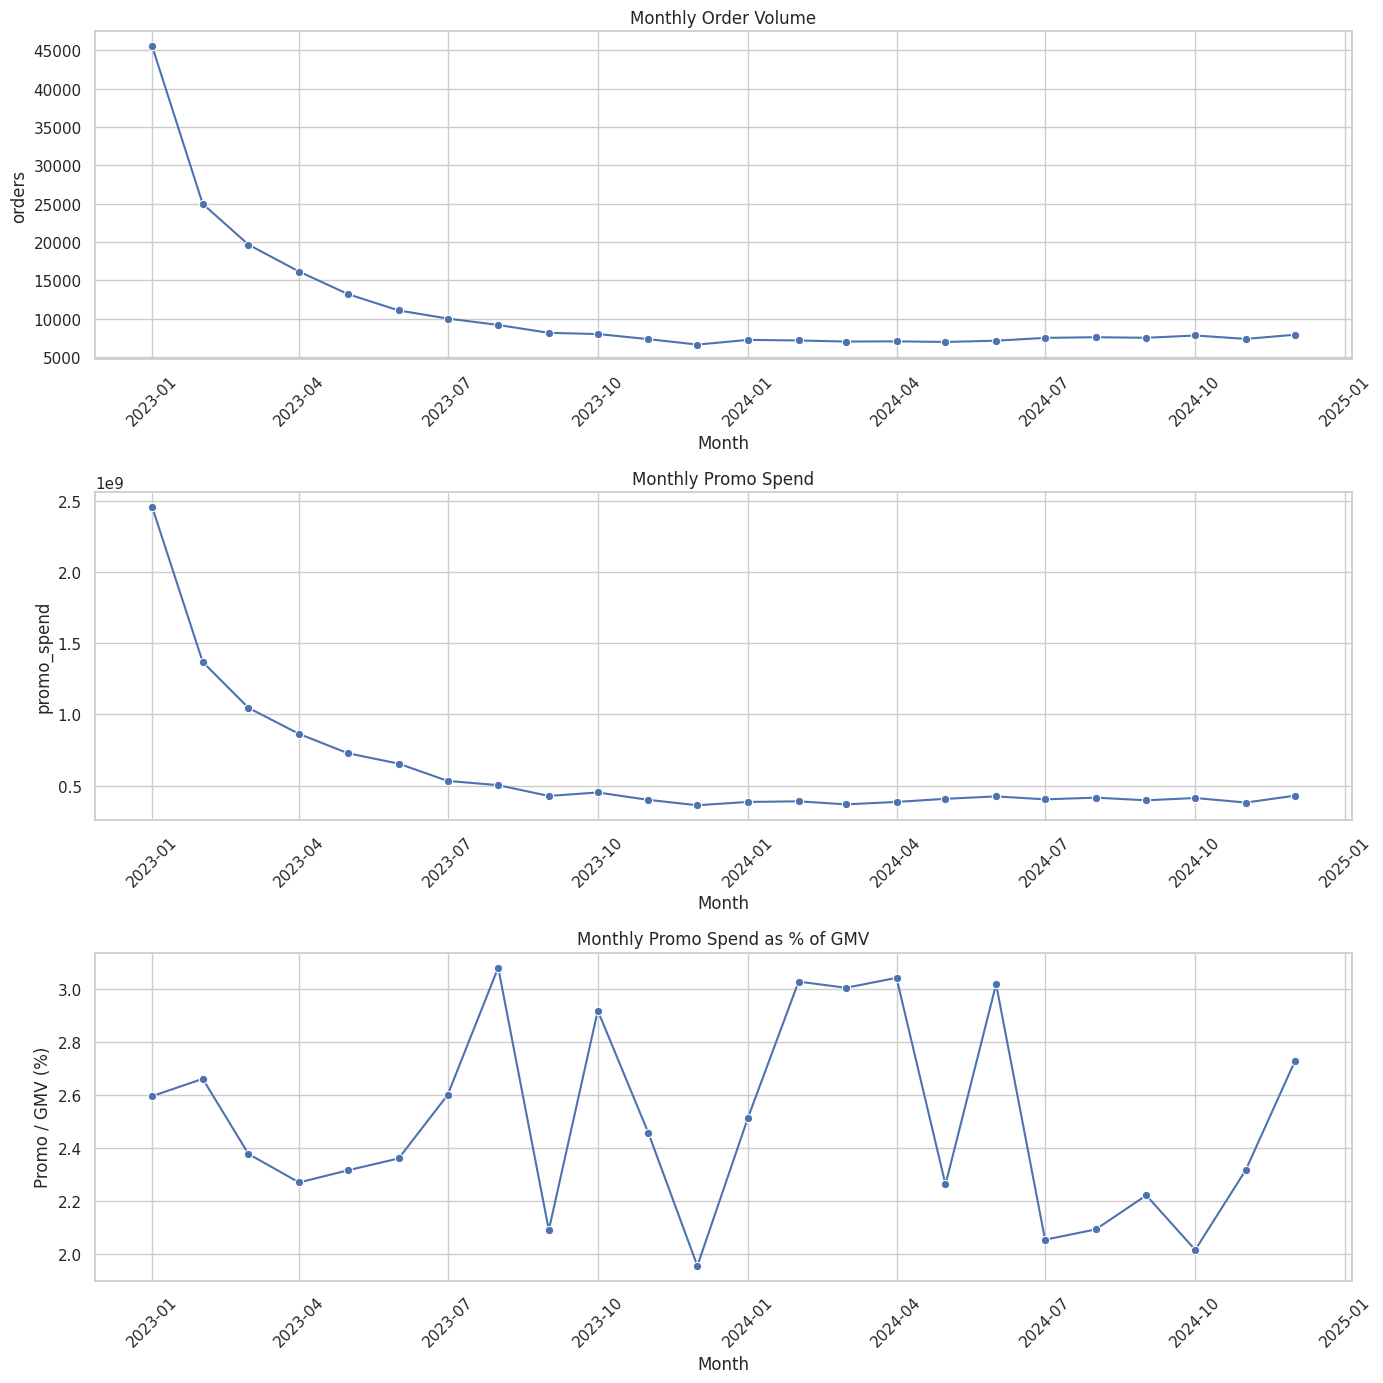

In [33]:
transactions["order_month"] = (
    transactions["order_date"].dt.to_period("M")
    .dt.to_timestamp()
)

monthly = (
    transactions[
        transactions["order_date"].between(
            "2023-01-01", "2024-12-31"
        )
    ]
    .groupby("order_month")
    .agg(
        orders=("order_id", "nunique"),
        users=("user_id", "nunique"),
        total_gmv=("total_amount", "sum"),
        promo_spend=("promo_amount", "sum"),
        shipping_subsidy=(
            "shipping_subsidy_platform", "sum"
        )
    )
    .reset_index()
)

monthly["promo_to_gmv"] = (
    monthly["promo_spend"]
    / monthly["total_gmv"].replace(0, np.nan)
    * 100
)

fig, axes = plt.subplots(3, 1, figsize=(14, 14))

sns.lineplot(
    data=monthly,
    x="order_month",
    y="orders",
    marker="o",
    ax=axes[0]
)
axes[0].set_title("Monthly Order Volume")

sns.lineplot(
    data=monthly,
    x="order_month",
    y="promo_spend",
    marker="o",
    ax=axes[1]
)
axes[1].set_title("Monthly Promo Spend")

sns.lineplot(
    data=monthly,
    x="order_month",
    y="promo_to_gmv",
    marker="o",
    ax=axes[2]
)
axes[2].set_title("Monthly Promo Spend as % of GMV")
axes[2].set_ylabel("Promo / GMV (%)")

for ax in axes:
    ax.set_xlabel("Month")
    ax.tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

In [34]:
completed = completed.sort_values(
    ["user_id", "order_date", "order_id"]
)

first_orders = (
    completed.drop_duplicates("user_id")
    [[
        "user_id",
        "order_id",
        "order_date",
        "promo_amount",
        "total_amount",
        "product_category",
        "is_campaign_period"
    ]]
    .rename(columns={
        "order_id": "first_order_id",
        "order_date": "first_order_date",
        "promo_amount": "first_order_promo",
        "total_amount": "first_order_amount",
        "product_category": "first_order_category",
        "is_campaign_period": "first_order_campaign"
    })
)

# Attach acquisition channel
first_orders = first_orders.merge(
    users[["user_id", "acquisition_channel"]],
    on="user_id",
    how="left",
    validate="one_to_one"
)

# Use a fixed end date for the study
study_end = pd.Timestamp("2024-12-31")

eligible = first_orders[
    first_orders["first_order_date"]
    <= study_end - pd.Timedelta(days=90)
].copy()

# Find subsequent completed orders within 90 days
subsequent = completed.merge(
    eligible[["user_id", "first_order_date"]],
    on="user_id",
    how="inner"
)

subsequent["days_since_first"] = (
    subsequent["order_date"]
    - subsequent["first_order_date"]
).dt.days

repeat_ids = subsequent.loc[
    subsequent["days_since_first"].between(1, 90),
    "user_id"
].unique()

eligible["repeat_90d"] = (
    eligible["user_id"].isin(repeat_ids).astype(int)
)

print("Eligible users:", len(eligible))
print("Repeat users:", eligible["repeat_90d"].sum())
print(
    "90-day repeat order rate:",
    round(eligible["repeat_90d"].mean() * 100, 2),
    "%"
)

Eligible users: 47376
Repeat users: 36266
90-day repeat order rate: 76.55 %


,acquisition_channel,users,repeat_users,repeat_rate,avg_first_promo,avg_first_order
0,ads,14308,11237,78.536483,55197.641389,1.959256e+06
1,affiliate,4687,3628,77.405590,53380.570728,1.971962e+06
2,organic,20987,16020,76.332968,54214.672512,2.251699e+06
3,referral,7079,5381,76.013561,58101.686114,2.369475e+06


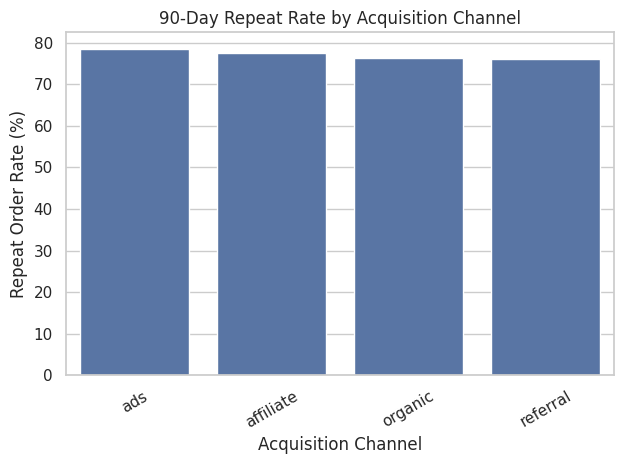

In [36]:
retention_channel = (
    eligible.groupby("acquisition_channel")
    .agg(
        users=("user_id", "nunique"),
        repeat_users=("repeat_90d", "sum"),
        repeat_rate=("repeat_90d", "mean"),
        avg_first_promo=("first_order_promo", "mean"),
        avg_first_order=("first_order_amount", "mean")
    )
    .reset_index()
)

retention_channel["repeat_rate"] *= 100

display(
    retention_channel.sort_values(
        "repeat_rate", ascending=False
    )
)

sns.barplot(
    data=retention_channel,
    x="acquisition_channel",
    y="repeat_rate"
)

plt.title("90-Day Repeat Rate by Acquisition Channel")
plt.xlabel("Acquisition Channel")
plt.ylabel("Repeat Order Rate (%)")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

,first_order_category,users,repeat_rate,avg_promo,avg_order_value
6,perabotan,5394,77.030033,55761.667037,2.489167e+06
3,kesehatan,6253,76.827123,57753.825844,1.244860e+06
1,fashion,11881,76.820133,53424.725107,2.147155e+06
2,grocery,8964,76.684516,54766.340250,9.880042e+05
4,lainnya,4815,76.427830,56431.728141,1.524386e+06
0,elektronik,6348,75.850662,51921.609326,5.514313e+06
5,olahraga,3721,75.544209,57577.872346,1.195977e+06


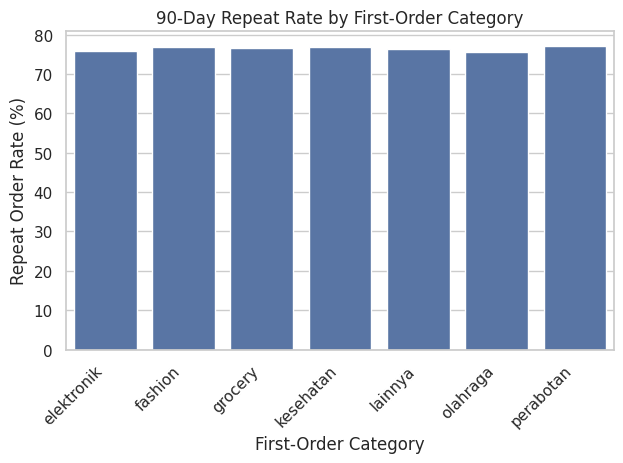

In [37]:
retention_category = (
    eligible.groupby("first_order_category")
    .agg(
        users=("user_id", "nunique"),
        repeat_rate=("repeat_90d", "mean"),
        avg_promo=("first_order_promo", "mean"),
        avg_order_value=("first_order_amount", "mean")).reset_index())

retention_category["repeat_rate"] *= 100

display(
    retention_category.sort_values("repeat_rate", ascending=False))

sns.barplot(
    data=retention_category,
    x="first_order_category",
    y="repeat_rate")

plt.title("90-Day Repeat Rate by First-Order Category")
plt.xlabel("First-Order Category")
plt.ylabel("Repeat Order Rate (%)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [63]:
# 1. Convert date columns to datetime objects across all DataFrames
transactions['order_date'] = pd.to_datetime(transactions['order_date'])
users['join_date'] = pd.to_datetime(users['join_date'])
deliveries['dispatch_date'] = pd.to_datetime(deliveries['dispatch_date'])
deliveries['delivery_date'] = pd.to_datetime(deliveries['delivery_date'])

# 2. Calculate actual delivery time and SLA breaches at the deliveries level
deliveries['actual_delivery_days'] = (deliveries['delivery_date'] - deliveries['dispatch_date']).dt.days
deliveries['is_sla_breached'] = (deliveries['actual_delivery_days'] > deliveries['sla_promised_days']).astype(int)

# 3. Merge Transactions with Users and Deliveries to create the master analytical dataset
df_master = transactions.merge(users[['user_id', 'acquisition_channel', 'join_date']], on='user_id', how='left')
df_master = df_master.merge(deliveries[['order_id', 'dispatch_date', 'delivery_date', 'is_sla_breached', 'courier_rating']], on='order_id', how='left')

# 4. ERASE ALL DATE ANOMALIES
# a. Remove impossible years (like 1970 or 2030)
df_master = df_master[(df_master['order_date'] >= '2023-01-01') & (df_master['order_date'] <= '2024-12-31')]

# b. Remove orders placed before the user joined
df_master = df_master[df_master['order_date'] >= df_master['join_date']]

# c. Remove orders dispatched before the order was placed
df_master = df_master[df_master['dispatch_date'] >= df_master['order_date']]

# d. Remove orders delivered before dispatch
df_master = df_master[df_master['delivery_date'] >= df_master['dispatch_date']]

# 5. Calculate the Promo Ratio
df_master['promo_ratio'] = df_master['promo_amount'] / df_master['total_amount']

# Verify clean shape and preview
print(f"Total rows remaining after erasing date anomalies: {len(df_master)}")
df_master[['order_id', 'order_date', 'dispatch_date', 'delivery_date', 'promo_ratio', 'is_sla_breached']].head()

Total rows remaining after erasing date anomalies: 260879


,order_id,order_date,dispatch_date,delivery_date,promo_ratio,is_sla_breached
0,INV/240811/8962287,2024-08-11,2024-08-17,2024-08-20,0.016091,0.0
1,INV/230311/4418494,2023-03-11,2023-03-11,2023-03-15,0.014672,0.0
2,INV/230114/7544472,2023-01-14,2023-01-14,2023-01-17,0.049614,1.0
3,INV/240207/1913666,2024-02-07,2024-02-08,2024-02-10,0.000000,0.0
4,INV/231111/7533488,2023-11-11,2023-11-12,2023-11-15,0.136411,0.0


In [65]:
# Determine if a user made more than 1 order
user_orders = df_master.groupby('user_id')['order_id'].count().reset_index()
user_orders['is_repeat_user'] = (user_orders['order_id'] > 1).astype(int)

# Isolate the user's FIRST order to check their initial experience
df_master['order_date'] = pd.to_datetime(df_master['order_date'])
first_orders = df_master.sort_values('order_date').drop_duplicates('user_id', keep='first')

# Merge the repeat status back to the first order experience
retention_analysis = first_orders.merge(user_orders[['user_id', 'is_repeat_user']], on='user_id')

# Calculate retention rate based on whether their first delivery was late
sla_impact = retention_analysis.groupby('is_sla_breached')['is_repeat_user'].mean().reset_index()
sla_impact.columns = ['Was First Delivery Late?', 'Repeat Order Rate']

display(sla_impact)

,Was First Delivery Late?,Repeat Order Rate
0,0.0,0.830093
1,1.0,0.715751


In [66]:
# 1. Aggregate Transactions to User-Level
user_metrics = transactions.groupby('user_id').agg(
    total_orders=('order_id', 'count'),
    total_gmv=('total_amount', 'sum'),
    total_promo=('promo_amount', 'sum'),
    first_order_date=('order_date', 'min'),
    last_order_date=('order_date', 'max')
).reset_index()

# Calculate how dependent each user is on promos overall
user_metrics['user_promo_ratio'] = user_metrics['total_promo'] / user_metrics['total_gmv']

# Create a flag for retention (Repeat Order Rate)
user_metrics['is_repeat'] = (user_metrics['total_orders'] > 1).astype(int)

# Merge acquisition channel from the users table
user_metrics = user_metrics.merge(users[['user_id', 'acquisition_channel']], on='user_id', how='left')

# 2. Rule-Based Customer Segmentation
import numpy as np

# Let's define the segments based on the case study's problem statement
conditions = [
    (user_metrics['user_promo_ratio'] > 0.10) & (user_metrics['is_repeat'] == 0), # High promo, churned immediately
    (user_metrics['user_promo_ratio'] <= 0.10) & (user_metrics['is_repeat'] == 1), # Low promo, repeats (High Value)
    (user_metrics['user_promo_ratio'] > 0.10) & (user_metrics['is_repeat'] == 1), # High promo, but stays loyal
]
choices = ['Discount Seekers (Churned)', 'High-Value Loyal', 'Promo-Driven Loyal']

# FIXED LINE: Added 'choices' here
user_metrics['user_segment'] = np.select(conditions, choices, default='One-Time (Low Promo)')

# 3. Analyze the Business Value of Each Segment
segment_analysis = user_metrics.groupby('user_segment').agg(
    user_count=('user_id', 'count'),
    total_gmv=('total_gmv', 'sum'),
    total_promo_spent=('total_promo', 'sum')
).reset_index()

# Calculate "Return on Promo" (GMV generated per Rp 1 of promo spent)
segment_analysis['return_on_promo'] = segment_analysis['total_gmv'] / segment_analysis['total_promo_spent']

# Calculate the percentage of total budget absorbed by each segment
total_promo_budget = segment_analysis['total_promo_spent'].sum()
segment_analysis['pct_of_promo_budget'] = (segment_analysis['total_promo_spent'] / total_promo_budget) * 100

display(segment_analysis.sort_values('pct_of_promo_budget', ascending=False))

,user_segment,user_count,total_gmv,total_promo_spent,return_on_promo,pct_of_promo_budget
3,Promo-Driven Loyal,8291,35493560501,7858212752,4.516747,53.675474
1,High-Value Loyal,33522,528827882689,6159821407,85.851171,42.074623
0,Discount Seekers (Churned),2113,735694464,531986956,1.382918,3.633734
2,One-Time (Low Promo),9058,26257167167,90208636,291.071546,0.616170


In [72]:
# 1. Calculate Financial Impact (Revenue at Risk / Budget Waste)
budget_waste = segment_analysis.loc[segment_analysis['user_segment'] == 'Discount Seekers (Churned)', 'total_promo_spent'].sum()
total_promo = segment_analysis['total_promo_spent'].sum()
waste_percentage = (budget_waste / total_promo) * 100

print(f"FINANCIAL IMPACT")
print(f"Total Promo Budget Spent: Rp {total_promo:,.0f}")
print(f"Budget Wasted on Churned Discount Seekers: Rp {budget_waste:,.0f}")
print(f"Percentage of Budget Wasted: {waste_percentage:.2f}%")


FINANCIAL IMPACT
Total Promo Budget Spent: Rp 14,640,229,751
Budget Wasted on Churned Discount Seekers: Rp 531,986,956
Percentage of Budget Wasted: 3.63%


--- SUMMARY TABLE ---
  promo_segment  users  repeat_rate     avg_promo  avg_order_value
0     Non-promo  21829    78.501077      0.000000     2.336063e+06
1         Promo  30458    78.494977  94985.262821     2.030248e+06


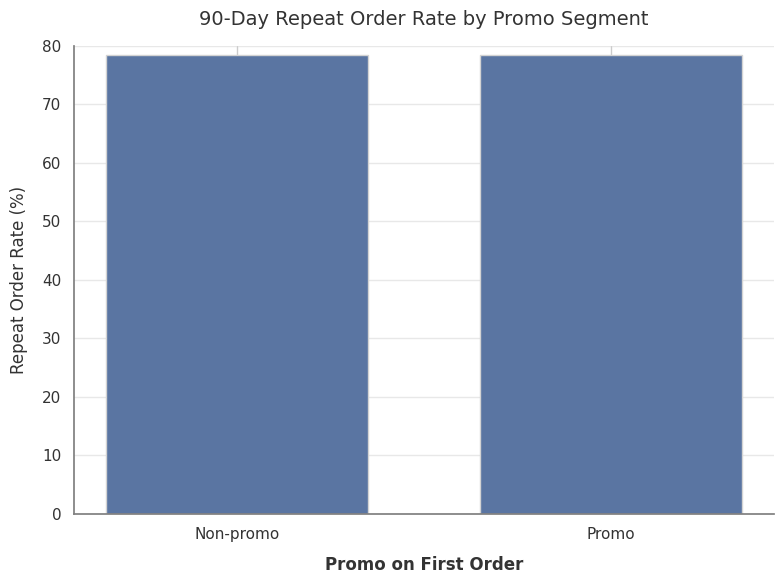

In [71]:
# Ensure date columns are datetime objects
df_master['order_date'] = pd.to_datetime(df_master['order_date'])

# Sort by user and date to accurately find the first purchase
df_master = df_master.sort_values(['user_id', 'order_date'])

# Extract First Order Details per User

first_orders = df_master.groupby('user_id').first().reset_index()

# Define Promo Segment on the First Order
first_orders['promo_segment'] = np.where(first_orders['promo_amount'] > 0, 'Promo', 'Non-promo')

# Calculate 90-Day Repeat Status

# Merge first order date back to the full dataset to compare subsequent order dates
df_merged = df_master.merge(
    first_orders[['user_id', 'order_date']],
    on='user_id',
    suffixes=('', '_first')
)

# Filter for orders that occurred AFTER the first order, but WITHIN 90 days
repeat_within_90 = df_merged[
    (df_merged['order_date'] > df_merged['order_date_first']) &
    (df_merged['order_date'] <= df_merged['order_date_first'] + pd.Timedelta(days=90))
]

# Get a unique set of user IDs who repeated within 90 days
users_repeated_90 = set(repeat_within_90['user_id'])

# Flag 90-day repeat users on the first_orders DataFrame
first_orders['is_repeat_90d'] = first_orders['user_id'].isin(users_repeated_90).astype(int)

# Generate the Summary DataFrame

summary_table = first_orders.groupby('promo_segment').agg(
    users=('user_id', 'count'),
    repeat_rate=('is_repeat_90d', lambda x: x.mean() * 100),
    avg_promo=('promo_amount', 'mean'),
    avg_order_value=('total_amount', 'mean')
).reset_index()

# Ensure Non-promo comes before Promo (matching the image)
summary_table['promo_segment'] = pd.Categorical(summary_table['promo_segment'], categories=['Non-promo', 'Promo'], ordered=True)
summary_table = summary_table.sort_values('promo_segment').reset_index(drop=True)

# Display Summary Table (Matches the top table in your image)
print("SUMMARY TABLE")
print(summary_table.to_string())

# Plot the Bar Chart (Matches the image)

plt.figure(figsize=(8, 6))

# Plot bars
bars = plt.bar(
    summary_table['promo_segment'],
    summary_table['repeat_rate'],
    color='#5A75A2',
    edgecolor='lightgrey',
    width=0.7
)

# Formatting chart to match image style
plt.title('90-Day Repeat Order Rate by Promo Segment', fontsize=14, pad=15, color='#333333')
plt.xlabel('Promo on First Order', fontsize=12, labelpad=10, fontweight='bold', color='#333333')
plt.ylabel('Repeat Order Rate (%)', fontsize=12, labelpad=10, color='#333333')

# Set Y-axis scale and grid
plt.ylim(0, 80)
plt.grid(axis='y', linestyle='-', alpha=0.5, color='lightgrey')
plt.gca().set_axisbelow(True)  # Grid behind bars

# Style ticks
plt.xticks(fontsize=11, color='#333333')
plt.yticks(fontsize=11, color='#333333')

# Remove top and right spines for a clean look
plt.gca().spines['top'].set_visible(False)
plt.gca().spines['right'].set_visible(False)
plt.gca().spines['left'].set_color('grey')
plt.gca().spines['bottom'].set_color('grey')

plt.tight_layout()
plt.show()

In [74]:
df_master['order_date'] = pd.to_datetime(df_master['order_date'])

# Convert courier_rating to float
df_master['courier_rating'] = df_master['courier_rating'].astype(float)

user_order_counts = df_master.groupby('user_id')['order_id'].nunique().reset_index()
user_order_counts['is_repeat_user'] = (user_order_counts['order_id'] > 1).astype(int)

df_master = df_master.drop(columns=['is_repeat_user'], errors='ignore')
df_master = df_master.merge(user_order_counts[['user_id', 'is_repeat_user']], on='user_id', how='left')

df_first = df_master.sort_values('order_date').drop_duplicates('user_id', keep='first').copy()

avg_ratings = df_first.groupby('is_repeat_user')['courier_rating'].agg(
    avg_courier_rating='mean',
    median_courier_rating='median',
    total_users='count'
).reset_index()

avg_ratings['status'] = np.where(avg_ratings['is_repeat_user'] == 1, 'Repeat User', 'Churned User')

print("--- AVERAGE COURIER RATING BY USER STATUS (FIRST ORDER) ---")
print(avg_ratings[['status', 'avg_courier_rating', 'median_courier_rating', 'total_users']].to_string(index=False))

bins = [0, 3.0, 4.0, 4.5, 5.0]
labels = ['Poor (< 3.0)', 'Average (3.0 - 4.0)', 'Good (4.0 - 4.5)', 'Excellent (4.5 - 5.0)']

df_first['rating_bucket'] = pd.cut(df_first['courier_rating'], bins=bins, labels=labels, include_lowest=True)

bucket_analysis = df_first.groupby('rating_bucket', observed=False).agg(
    total_users=('user_id', 'count'),
    repeat_users=('is_repeat_user', 'sum'),
    repeat_rate=('is_repeat_user', lambda x: x.mean() * 100),
    churn_rate=('is_repeat_user', lambda x: (1 - x.mean()) * 100)
).reset_index()

print("\n--- IMPACT OF FIRST-ORDER COURIER RATING ON REPEAT RATE & CHURN ---")
print(bucket_analysis.to_string(index=False))

valid_ratings = df_first.dropna(subset=['courier_rating', 'is_repeat_user'])
correlation = valid_ratings['courier_rating'].corr(valid_ratings['is_repeat_user'])

print(f"\nCorrelation between Courier Rating and Repeat Order Status: {correlation:.4f}")

--- AVERAGE COURIER RATING BY USER STATUS (FIRST ORDER) ---
      status  avg_courier_rating  median_courier_rating  total_users
Churned User            4.312395                    4.6        11004
 Repeat User            4.539520                    4.6        41283

--- IMPACT OF FIRST-ORDER COURIER RATING ON REPEAT RATE & CHURN ---
        rating_bucket  total_users  repeat_users  repeat_rate  churn_rate
         Poor (< 3.0)         1511           460    30.443415   69.556585
  Average (3.0 - 4.0)         4070          3072    75.479115   24.520885
     Good (4.0 - 4.5)        12374         10435    84.330047   15.669953
Excellent (4.5 - 5.0)        34332         27316    79.564255   20.435745

Correlation between Courier Rating and Repeat Order Status: 0.1868


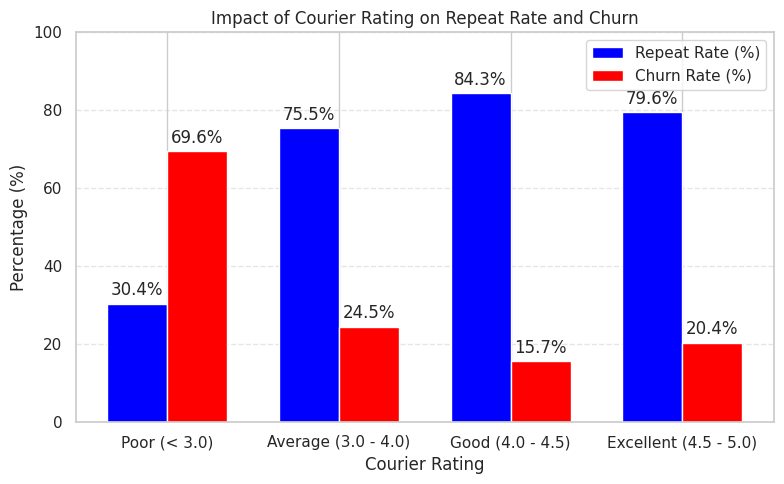

In [76]:
x = np.arange(len(bucket_analysis['rating_bucket']))
width = 0.35

fig, ax = plt.subplots(figsize=(8, 5))

# Plot bars: blue for Repeat Rate, red for Churn Rate
rects1 = ax.bar(x - width/2, bucket_analysis['repeat_rate'], width, label='Repeat Rate (%)', color='blue')
rects2 = ax.bar(x + width/2, bucket_analysis['churn_rate'], width, label='Churn Rate (%)', color='red')

ax.set_xlabel('Courier Rating')
ax.set_ylabel('Percentage (%)')
ax.set_title('Impact of Courier Rating on Repeat Rate and Churn')
ax.set_xticks(x)
ax.set_xticklabels(bucket_analysis['rating_bucket'])
ax.set_ylim(0, 100)
ax.legend()
ax.grid(axis='y', linestyle='--', alpha=0.5)

# Add value labels on top of each bar
for bar in rects1:
    h = bar.get_height()
    ax.annotate(f'{h:.1f}%', xy=(bar.get_x() + bar.get_width() / 2, h),
                xytext=(0, 3), textcoords="offset points", ha='center', va='bottom')

for bar in rects2:
    h = bar.get_height()
    ax.annotate(f'{h:.1f}%', xy=(bar.get_x() + bar.get_width() / 2, h),
                xytext=(0, 3), textcoords="offset points", ha='center', va='bottom')

plt.tight_layout()
plt.show()

In [81]:
# Ensure repeat order status per user is calculated
user_order_counts = df_master.groupby('user_id')['order_id'].nunique().reset_index()
user_order_counts['is_repeat_user'] = (user_order_counts['order_id'] > 1).astype(int)

df_master = df_master.drop(columns=['is_repeat_user'], errors='ignore')
df_master = df_master.merge(user_order_counts[['user_id', 'is_repeat_user']], on='user_id', how='left')

# Group by Acquisition Channel to compute metrics
channel_summary = df_master.groupby('acquisition_channel').agg(
    total_promo=('promo_amount', 'sum'),
    total_gmv=('total_amount', 'sum'),
    repeat_rate=('is_repeat_user', lambda x: x.mean() * 100)
).reset_index()

# 1. Promo Spend Share (%)
total_promo_all = channel_summary['total_promo'].sum()
channel_summary['Promo Spend Share'] = (channel_summary['total_promo'] / total_promo_all) * 100

# 2. Return on Promo (GMV / Promo Spend)
channel_summary['Return on Promo'] = channel_summary['total_gmv'] / channel_summary['total_promo']

channel_summary = channel_summary.rename(columns={
    'acquisition_channel': 'Channel',
    'repeat_rate': 'Repeat Order Rate'
})

channel_summary = channel_summary.sort_values('Promo Spend Share', ascending=False).reset_index(drop=True)

print("--- CHANNEL PERFORMANCE SUMMARY ---")
for _, row in channel_summary.iterrows():
    print(f"Channel: {row['Channel']}")
    print(f"  Promo Spend Share : {row['Promo Spend Share']:.1f}%")
    print(f"  Repeat Order Rate : {row['Repeat Order Rate']:.1f}%")
    print(f"  Return on Promo   : {row['Return on Promo']:.1f}x\n")

--- CHANNEL PERFORMANCE SUMMARY ---
Channel: organic
  Promo Spend Share : 41.9%
  Repeat Order Rate : 95.3%
  Return on Promo   : 40.5x

Channel: ads
  Promo Spend Share : 33.5%
  Repeat Order Rate : 96.4%
  Return on Promo   : 39.1x

Channel: referral
  Promo Spend Share : 14.8%
  Repeat Order Rate : 95.6%
  Return on Promo   : 42.1x

Channel: affiliate
  Promo Spend Share : 9.8%
  Repeat Order Rate : 95.9%
  Return on Promo   : 40.9x



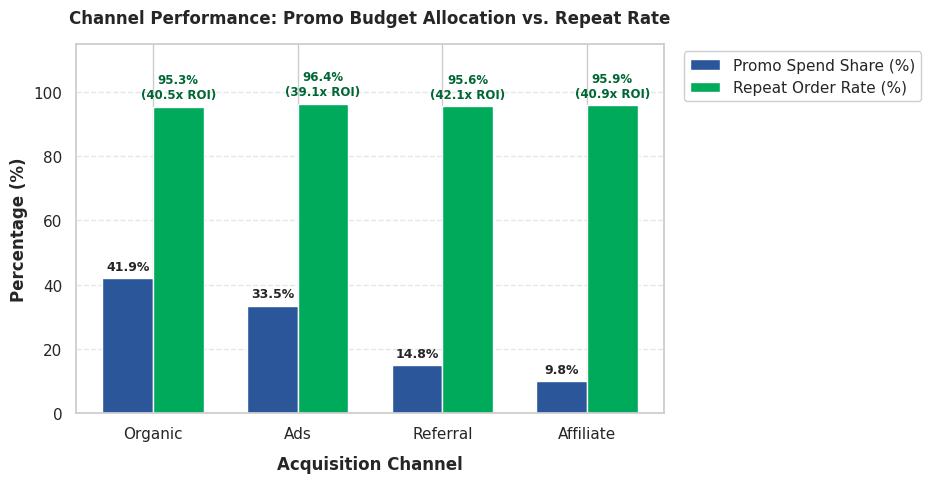

In [83]:
x = np.arange(len(channel_summary['Channel']))
width = 0.35

fig, ax = plt.subplots(figsize=(9.5, 5))

# Plot bars: Blue for Promo Spend Share, Green for Repeat Rate
rects1 = ax.bar(x - width/2, channel_summary['Promo Spend Share'], width, label='Promo Spend Share (%)', color='#2B579A')
rects2 = ax.bar(x + width/2, channel_summary['Repeat Order Rate'], width, label='Repeat Order Rate (%)', color='#00AA5B')

ax.set_xlabel('Acquisition Channel', fontweight='bold', labelpad=10)
ax.set_ylabel('Percentage (%)', fontweight='bold')
ax.set_title('Channel Performance: Promo Budget Allocation vs. Repeat Rate', fontweight='bold', pad=15)
ax.set_xticks(x)
ax.set_xticklabels(channel_summary['Channel'].str.title())

ax.set_ylim(0, 115)
ax.grid(axis='y', linestyle='--', alpha=0.5)

ax.legend(bbox_to_anchor=(1.02, 1), loc='upper left', frameon=True, facecolor='white', edgecolor='#BDC3C7')

# Add data labels on top of bars
for bar in rects1:
    h = bar.get_height()
    ax.annotate(f'{h:.1f}%', xy=(bar.get_x() + bar.get_width() / 2, h),
                xytext=(0, 4), textcoords="offset points", ha='center', va='bottom', fontsize=9, fontweight='bold')

for bar, roi in zip(rects2, channel_summary['Return on Promo']):
    h = bar.get_height()
    ax.annotate(f'{h:.1f}%\n({roi:.1f}x ROI)', xy=(bar.get_x() + bar.get_width() / 2, h),
                xytext=(0, 4), textcoords="offset points", ha='center', va='bottom', fontsize=8.5, fontweight='bold', color='#006633')

plt.tight_layout()
plt.show()

In [68]:
# Export Data for Tableau
# Export the user-level segmentation for your demographic and CLV/CAC dashboards
user_metrics.to_excel('tableau_user_segmentation.xlsx', index=False)

# Export the transaction-level data for your logistics, SLA, and time-series dashboards
# Make sure order_date is nicely formatted for Tableau
df_master['order_date'] = pd.to_datetime(df_master['order_date']).dt.strftime('%Y-%m-%d')
df_master.to_excel('tableau_transaction_master.xlsx', index=False)

In [84]:
# Data cleaning: fill voucher_type logic
df_master['voucher_type'] = np.where(
    df_master['voucher_type'].isna() & (df_master['promo_amount'] == 0),
    'no voucher',
    df_master['voucher_type']
)
df_master['voucher_type'] = df_master['voucher_type'].fillna('unknown')

# Determine repeat user status per user
user_order_counts = df_master.groupby('user_id')['order_id'].nunique().reset_index()
user_order_counts['is_repeat_user'] = (user_order_counts['order_id'] > 1).astype(int)

df_master = df_master.drop(columns=['is_repeat_user'], errors='ignore')
df_master = df_master.merge(user_order_counts[['user_id', 'is_repeat_user']], on='user_id', how='left')

# Isolate first order to test acquisition incentive impact
df_first = df_master.sort_values('order_date').drop_duplicates('user_id', keep='first').copy()

# Group by voucher type on first order
voucher_analysis = df_first.groupby('voucher_type', observed=False).agg(
    total_users=('user_id', 'count'),
    repeat_users=('is_repeat_user', 'sum'),
    repeat_rate=('is_repeat_user', lambda x: x.mean() * 100),
    churn_rate=('is_repeat_user', lambda x: (1 - x.mean()) * 100),
    avg_promo_given=('promo_amount', 'mean')
).reset_index()

voucher_analysis['user_share'] = (voucher_analysis['total_users'] / voucher_analysis['total_users'].sum()) * 100
voucher_analysis = voucher_analysis.sort_values('total_users', ascending=False).reset_index(drop=True)

print("--- VOUCHER TYPE IMPACT ON RETENTION (FIRST ORDER) ---")
print(voucher_analysis[['voucher_type', 'total_users', 'user_share', 'repeat_rate', 'churn_rate', 'avg_promo_given']].to_string(index=False))

# Overall platform voucher spend share and ROI across all orders
voucher_overall = df_master.groupby('voucher_type', observed=False).agg(
    total_orders=('order_id', 'count'),
    total_promo_spent=('promo_amount', 'sum'),
    total_gmv=('total_amount', 'sum')
).reset_index()

voucher_overall['spend_share'] = (voucher_overall['total_promo_spent'] / voucher_overall['total_promo_spent'].sum()) * 100
voucher_overall['roi_multiple'] = np.where(
    voucher_overall['total_promo_spent'] > 0,
    voucher_overall['total_gmv'] / voucher_overall['total_promo_spent'],
    np.nan
)

print("\n--- OVERALL VOUCHER SPEND SHARE & ROI ---")
print(voucher_overall[['voucher_type', 'total_orders', 'spend_share', 'roi_multiple']].to_string(index=False))

--- VOUCHER TYPE IMPACT ON RETENTION (FIRST ORDER) ---
 voucher_type  total_users  user_share  repeat_rate  churn_rate  avg_promo_given
   no voucher        21828   41.746514    78.926150   21.073850         0.000000
  free_ongkir        12107   23.154895    79.367308   20.632692     83917.313290
     cashback         9197   17.589458    78.264652   21.735348    102072.009786
diskon_persen         9155   17.509132    79.169853   20.830147    102584.055816

--- OVERALL VOUCHER SPEND SHARE & ROI ---
 voucher_type  total_orders  spend_share  roi_multiple
     cashback         46008    32.998962     20.994606
diskon_persen         45712    32.760960     20.974532
  free_ongkir         59679    34.240078     26.837377
   no voucher        109480     0.000000           NaN


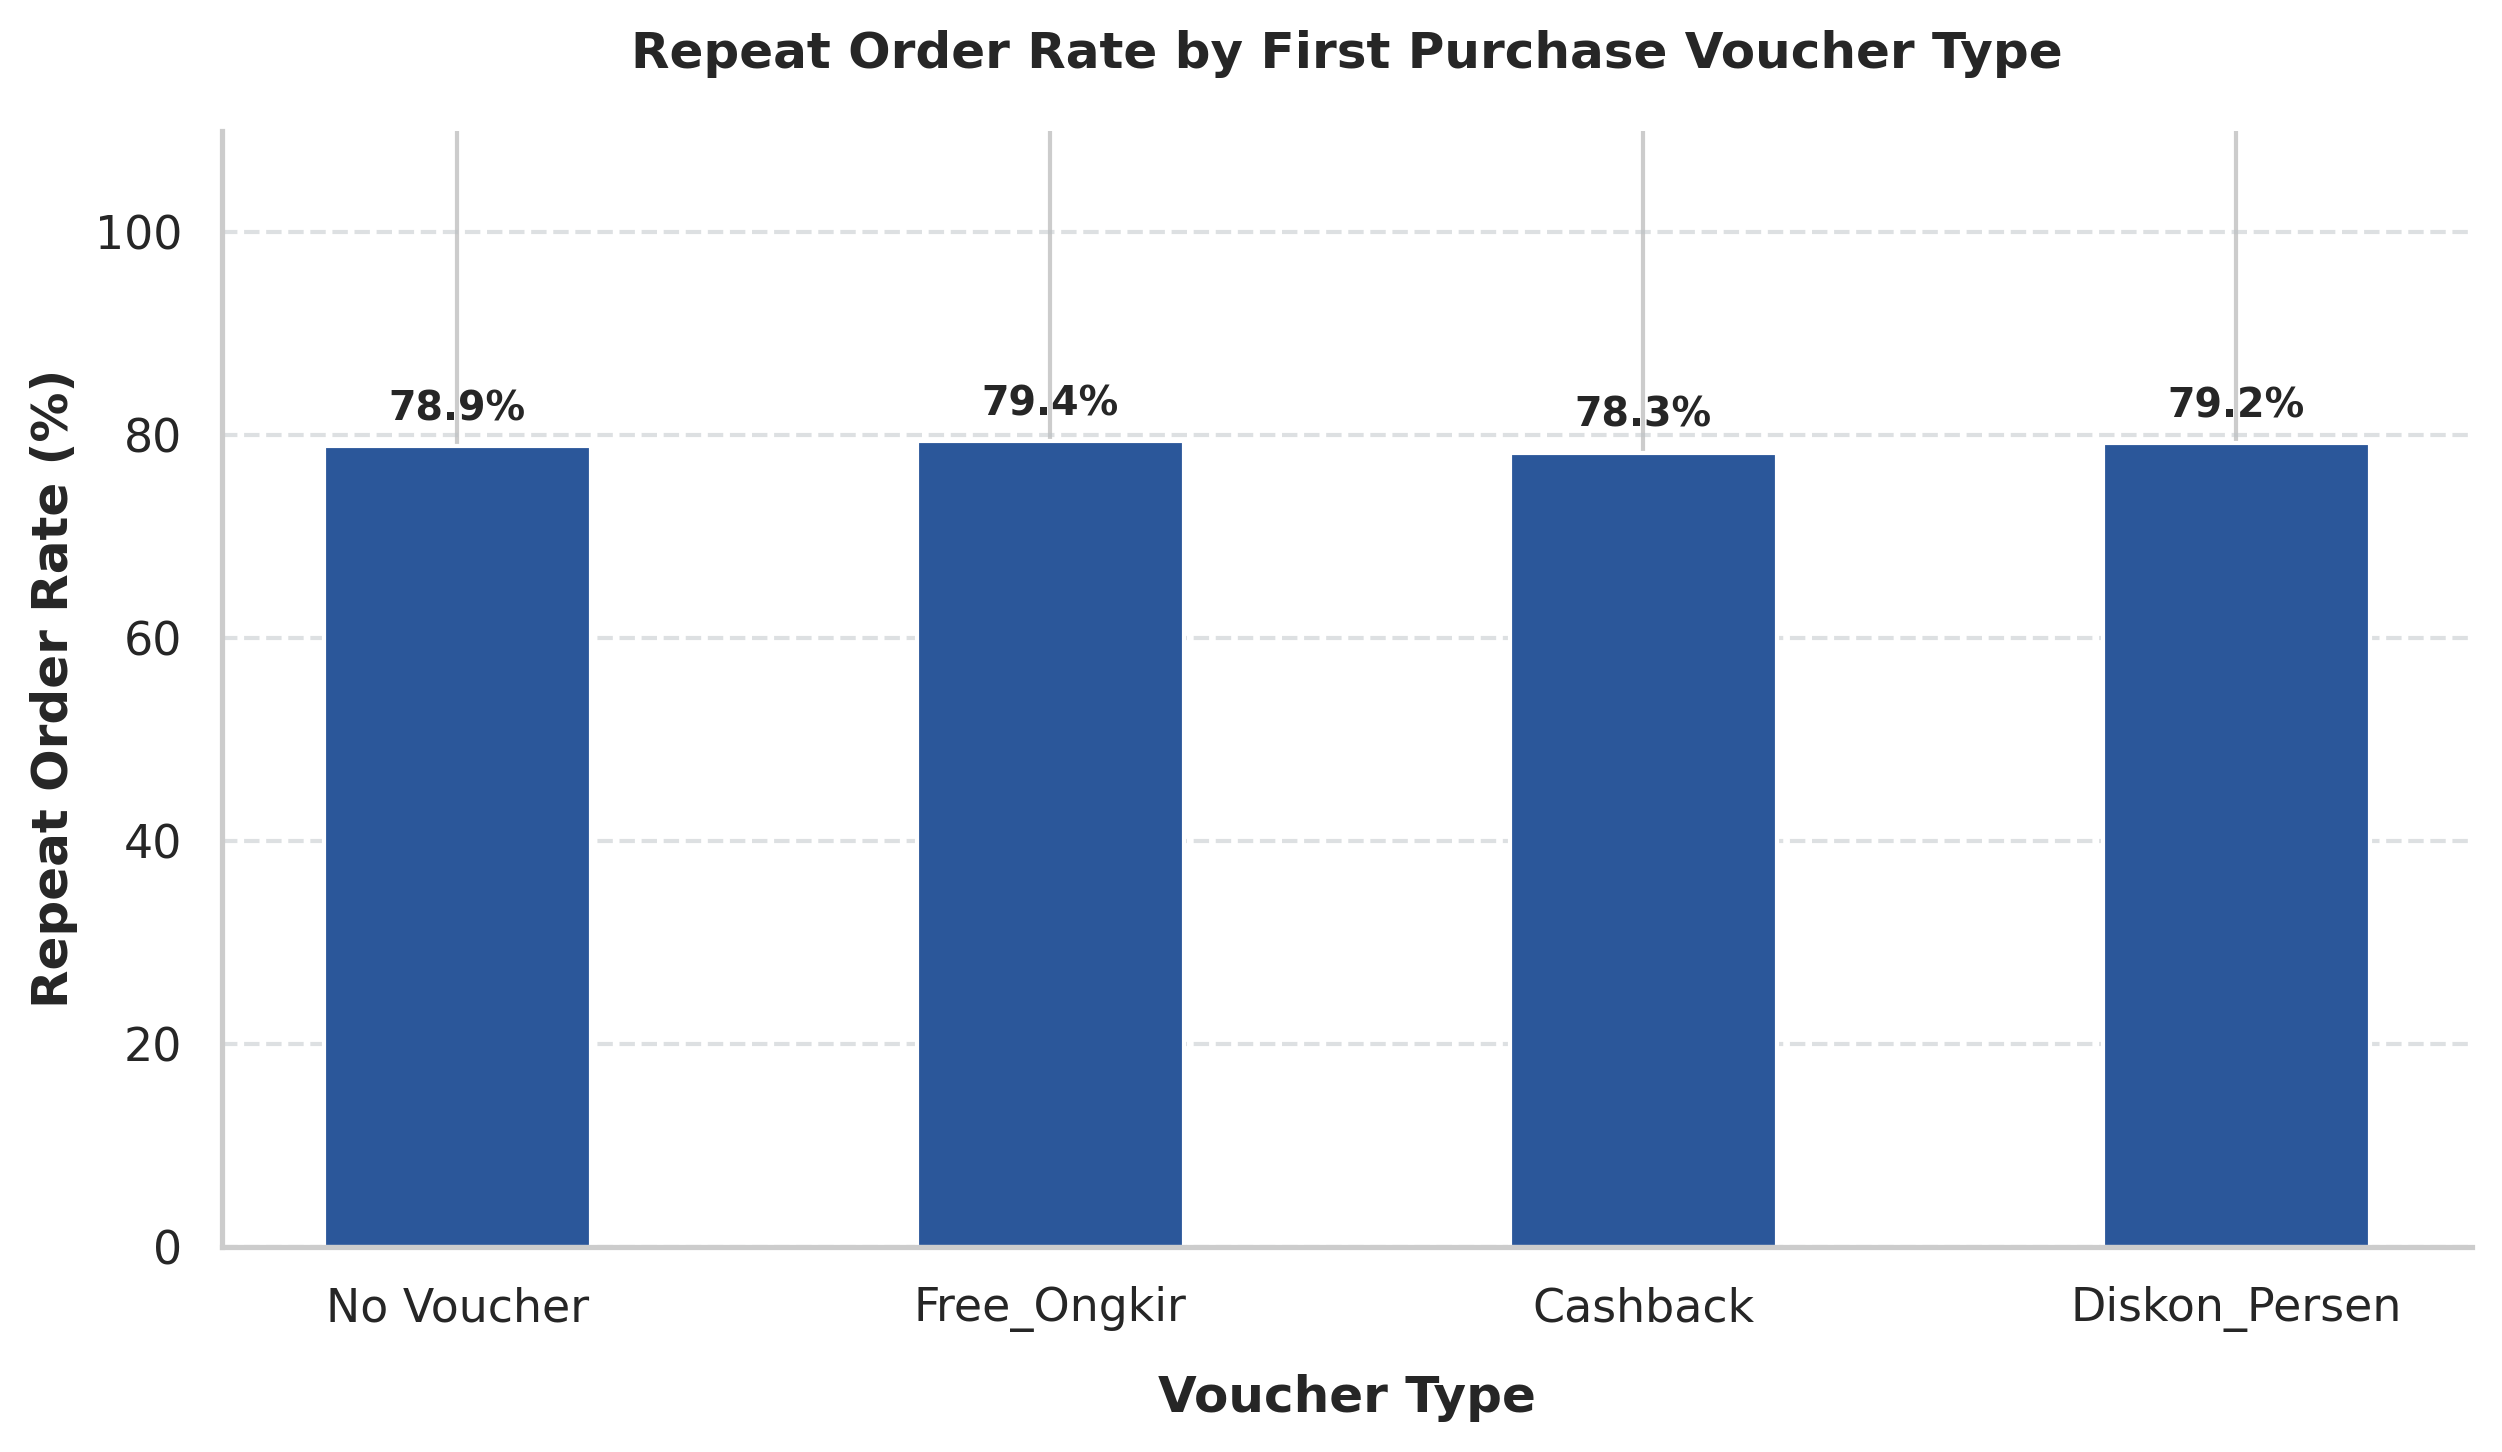

In [85]:
fig, ax = plt.subplots(figsize=(8.5, 5), dpi=300)

bars = ax.bar(
    voucher_analysis['voucher_type'].str.title(),
    voucher_analysis['repeat_rate'],
    color='#2B579A',
    width=0.45
)

ax.set_title('Repeat Order Rate by First Purchase Voucher Type', fontweight='bold', fontsize=12, pad=15)
ax.set_xlabel('Voucher Type', fontweight='bold', labelpad=10)
ax.set_ylabel('Repeat Order Rate (%)', fontweight='bold')
ax.set_ylim(0, 110)

ax.grid(axis='y', linestyle='--', alpha=0.5, color='#BDC3C7')
ax.set_axisbelow(True)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

for bar in bars:
    h = bar.get_height()
    ax.annotate(
        f'{h:.1f}%',
        xy=(bar.get_x() + bar.get_width() / 2, h),
        xytext=(0, 4), textcoords="offset points",
        ha='center', va='bottom', fontsize=9.5, fontweight='bold'
    )

plt.tight_layout()
plt.savefig('voucher_type_repeat_rate.png', bbox_inches='tight')
plt.show()

In [99]:
df_master['shipping_cost_charged_to_user'] = df_master['shipping_cost_charged_to_user'].astype(float)

# Determine repeat user status per user
user_order_counts = df_master.groupby('user_id')['order_id'].nunique().reset_index()
user_order_counts['is_repeat_user'] = (user_order_counts['order_id'] > 1).astype(int)

df_master = df_master.drop(columns=['is_repeat_user'], errors='ignore')
df_master = df_master.merge(user_order_counts[['user_id', 'is_repeat_user']], on='user_id', how='left')

# Isolate first purchase to inspect friction
df_first = df_master.sort_values('order_date').drop_duplicates('user_id', keep='first').copy()

# Average & median shipping fee by repeat status
shipping_user_stat = df_first.groupby('is_repeat_user')['shipping_cost_charged_to_user'].agg(
    avg_shipping_cost='mean',
    median_shipping_cost='median'
).reset_index()
shipping_user_stat['status'] = np.where(shipping_user_stat['is_repeat_user'] == 1, 'Repeat User', 'Churned User')

print("--- FIRST-ORDER SHIPPING COST BY USER STATUS ---")
print(shipping_user_stat[['status', 'avg_shipping_cost', 'median_shipping_cost']].to_string(index=False))

# Categorize shipping costs into tiers
quantiles = [0, 1, 5000, 150000, np.inf]
shipping_labels = ['Free Shipping (0)', 'Low (1 - 5k)', 'Medium (5k - 15k)', 'High (> 15k)']

df_first['shipping_bucket'] = pd.cut(df_first['shipping_cost_charged_to_user'], bins=quantiles, labels=shipping_labels, right=False)

shipping_bucket_analysis = df_first.groupby('shipping_bucket', observed=False).agg(
    total_users=('user_id', 'count'),
    repeat_users=('is_repeat_user', 'sum'),
    repeat_rate=('is_repeat_user', lambda x: x.mean() * 100),
    churn_rate=('is_repeat_user', lambda x: (1 - x.mean()) * 100)
).reset_index()

print("\n SHIPPING COST TIER VS CHURN & RETENTION")
print(shipping_bucket_analysis.to_string(index=False))

--- FIRST-ORDER SHIPPING COST BY USER STATUS ---
      status  avg_shipping_cost  median_shipping_cost
Churned User       10099.570702                9913.5
 Repeat User       10478.720272               10285.0

 SHIPPING COST TIER VS CHURN & RETENTION
  shipping_bucket  total_users  repeat_users  repeat_rate  churn_rate
Free Shipping (0)            0             0          NaN         NaN
     Low (1 - 5k)         9224          7019    76.094970   23.905030
Medium (5k - 15k)        43063         34264    79.567146   20.432854
     High (> 15k)            0             0          NaN         NaN


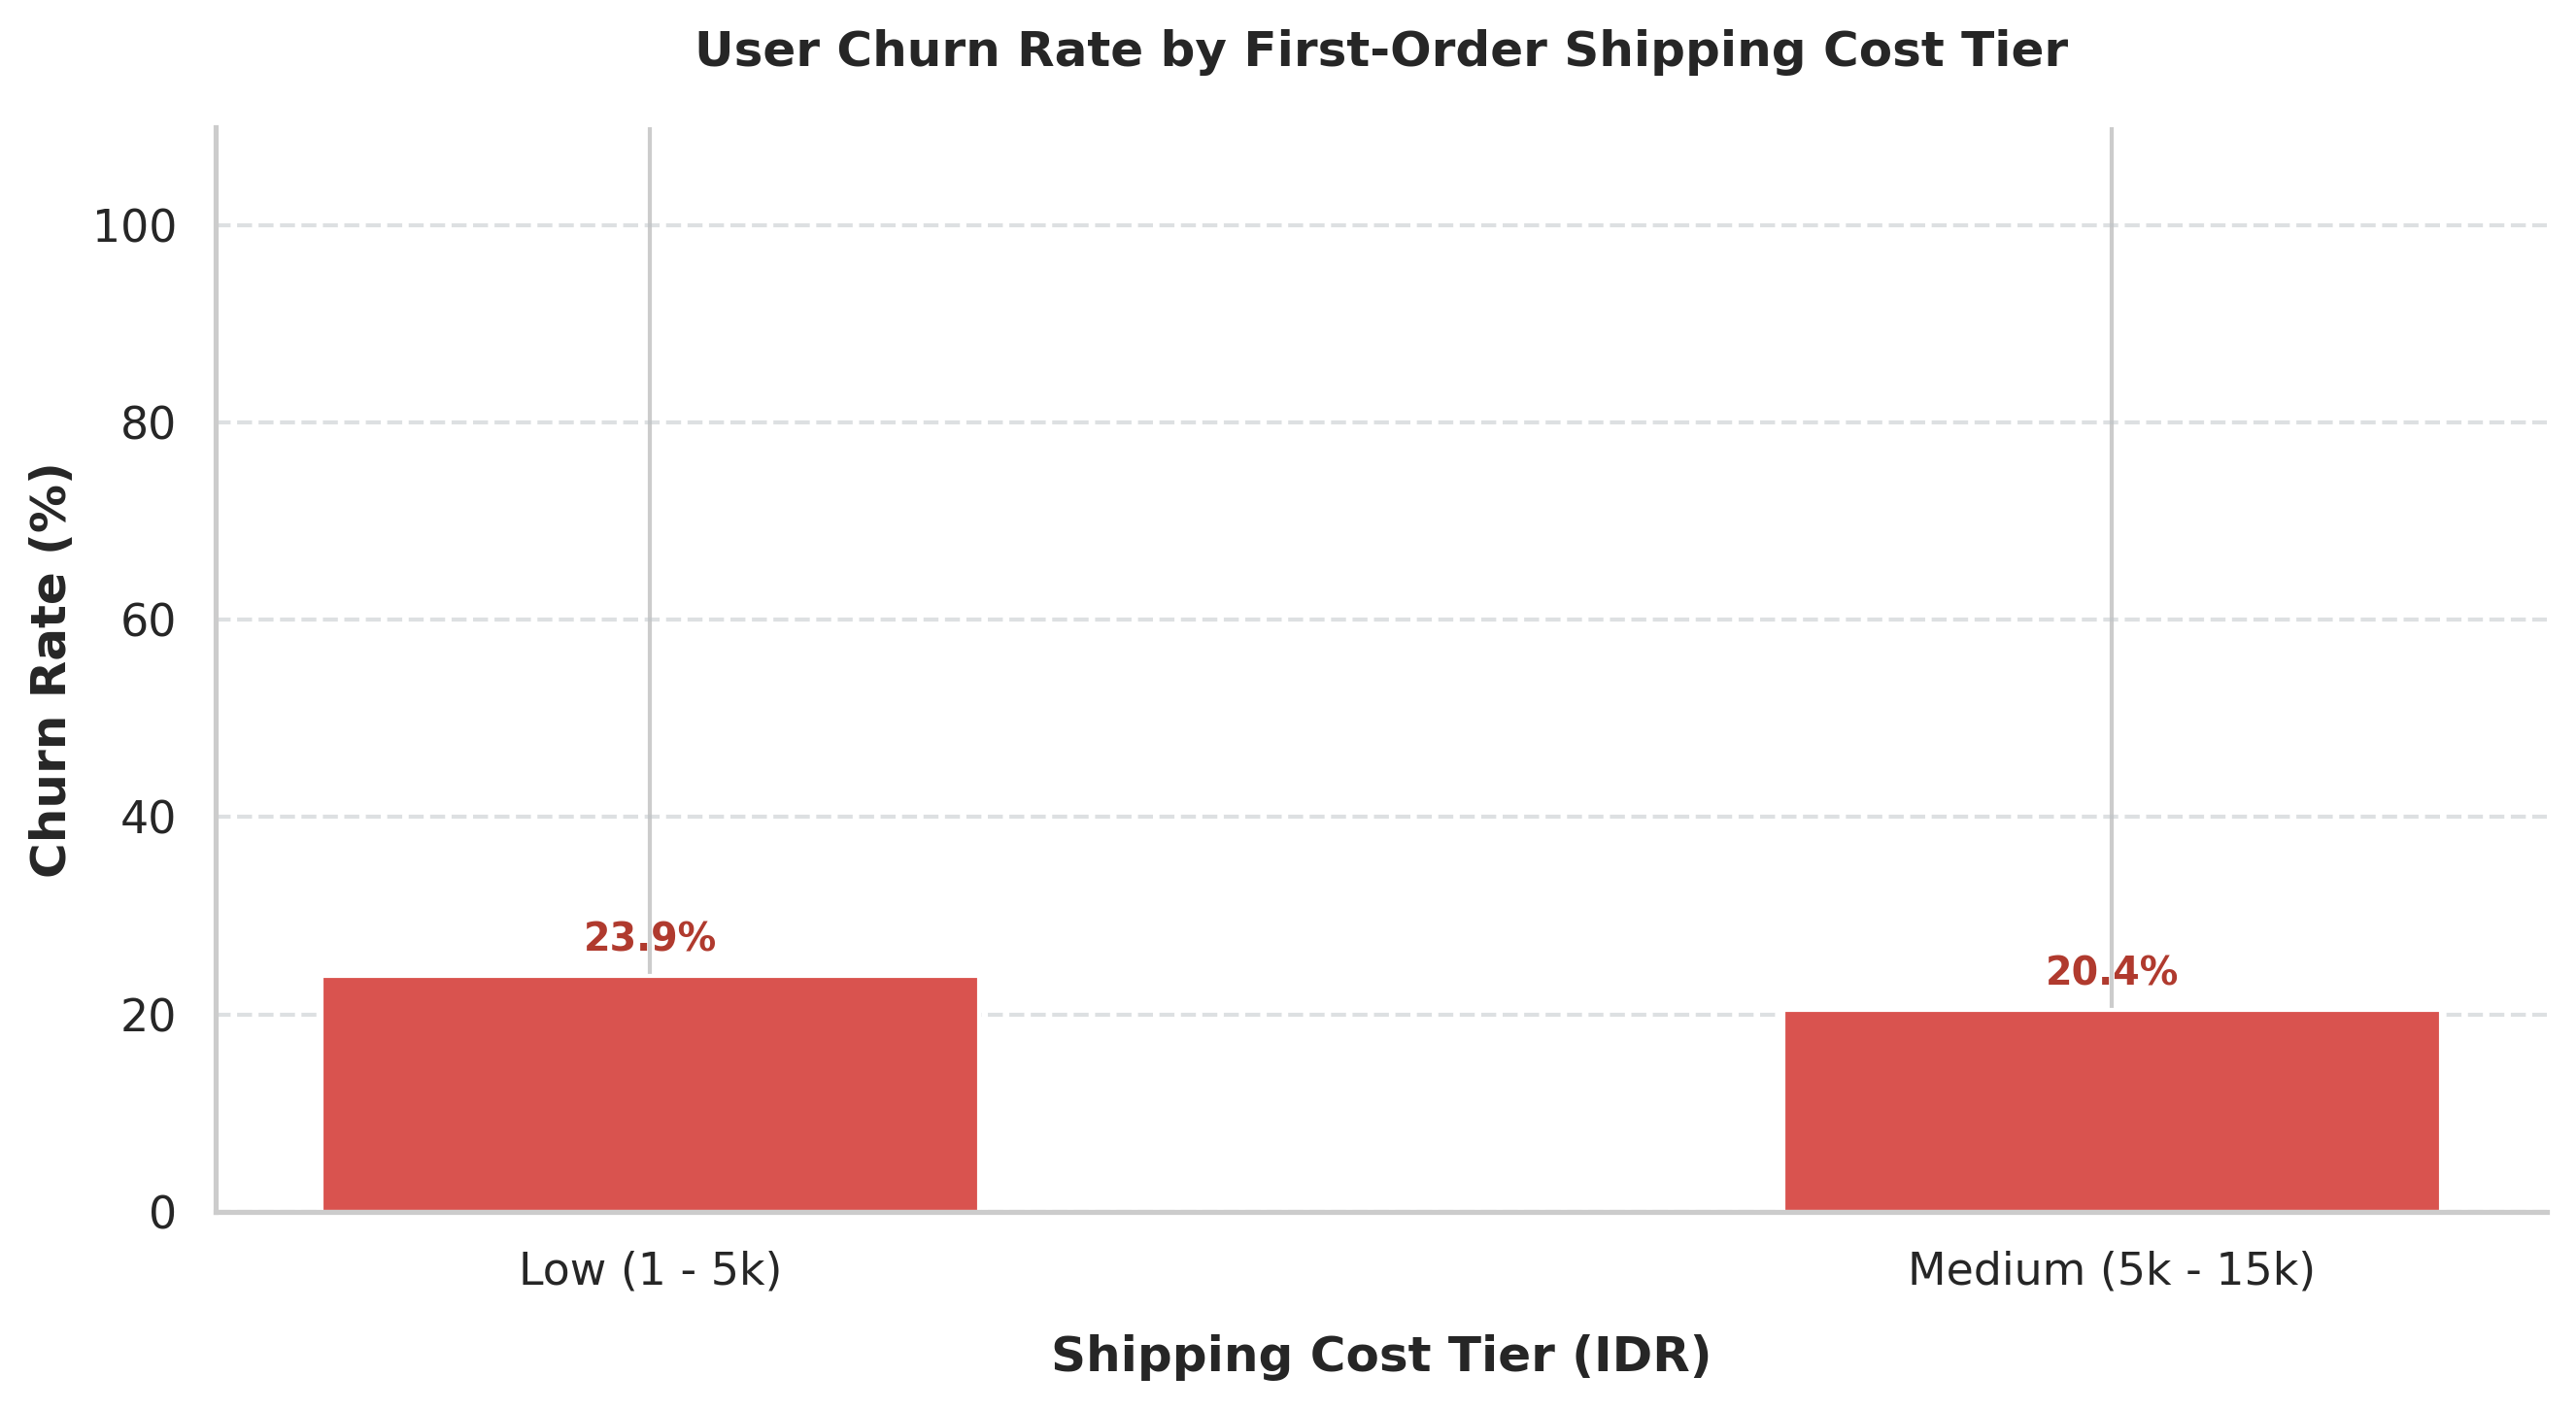

In [100]:
fig, ax = plt.subplots(figsize=(9, 5), dpi=300)

bars = ax.bar(
    shipping_bucket_analysis['shipping_bucket'].astype(str),
    shipping_bucket_analysis['churn_rate'],
    color='#D9534F',
    width=0.45
)

ax.set_title('User Churn Rate by First-Order Shipping Cost Tier', fontweight='bold', fontsize=12, pad=15)
ax.set_xlabel('Shipping Cost Tier (IDR)', fontweight='bold', labelpad=10)
ax.set_ylabel('Churn Rate (%)', fontweight='bold')
ax.set_ylim(0, 110)

ax.grid(axis='y', linestyle='--', alpha=0.5, color='#BDC3C7')
ax.set_axisbelow(True)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

for bar in bars:
    h = bar.get_height()
    ax.annotate(
        f'{h:.1f}%',
        xy=(bar.get_x() + bar.get_width() / 2, h),
        xytext=(0, 4), textcoords="offset points",
        ha='center', va='bottom', fontsize=9.5, fontweight='bold', color='#B03A2E'
    )

plt.tight_layout()
plt.savefig('shipping_cost_churn_rate.png', bbox_inches='tight')
plt.show()